# Portfolio Construction: Estimation Risk Meets Portfolio Choice


## Outline
1. **The Failure, Given** — singular sample covariance, inverse versus pseudo-inverse.
2. **Build and Validate the Covariance** — sector factors, fixed-book forecasts, optimized-book forecasts, one alternative.
3. **Minimum Variance** — benchmarks, stabilization, and long-only GMV.
4. **The Mean Input** — sample, shrunk, and CAPM means; estimation uncertainty.
5. **The Book's Own Risk** — daily historical, factor-normal, and EWMA VaR and tail losses.
6. **Pricing the Names** — cross-sectional CAPM and the DFA joint-alpha test.
7. **Build Your Book** — declared design, costs, evaluation, and one sensitivity test.

### Reproduction and conventions
Run all cells in order with the notebook directory as the working directory. The three supplied files must be in its `data` subfolder. Dependencies: NumPy, pandas, SciPy, matplotlib, openpyxl, pyarrow, and an IPython/Jupyter kernel. No downloads or output files are created by the notebook.

Unless stated otherwise: 457 static complete-history names and the supplied GICS labels; weekly excess returns; 104-week estimation windows including the signal date; signals every four weeks from 2017-10-06; weights first earn the following week's return and remain at their targets, without drift. Annualization uses 52 (weekly) or 252 (daily). Realized variance always uses `ddof=1`. Covariance residual moments use the same denominator as the return covariance so the full-residual reconstruction is exact.

A leveraged weekly book is self-financing: total return is portfolio excess return plus one bill return, with residual wealth in cash. Turnover is the brief's change in target weights, not trading required to undo interim drift. Predictions are averaged over signal dates, including the final short holding period. Results are gross of costs until Section 7.

Each numbered question reproduces its complete wording from `Brief.ipynb` before the answer. All analysis and code are in English.

In [1]:
from pathlib import Path
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.linalg import cho_factor, cho_solve
from scipy.optimize import nnls
from scipy.stats import norm, chi2, f as f_dist
from IPython.display import display, Markdown

%matplotlib inline
plt.rcParams.update({'figure.figsize': (10, 4), 'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': 0.2})
pd.set_option('display.max_columns', 15)

# Locate the supplied data without hard-coding an operating-system-specific path.
DATA_DIR = Path('data')
if not DATA_DIR.is_dir() and (Path('Midterm_Project') / 'data').is_dir():
    DATA_DIR = Path('Midterm_Project') / 'data'
WEEKLY = DATA_DIR / 'spx_returns_weekly.xlsx'
DAILY = DATA_DIR / 'spx_returns_daily_full.parquet'
SECTOR_DAILY = DATA_DIR / 'sector_etf_data_daily.xlsx'
for path in (WEEKLY, DAILY, SECTOR_DAILY):
    if not path.is_file():
        raise FileNotFoundError(f'Missing {path.resolve()}. Run from the notebook directory with data beside it.')

FREQ, WINDOW, STEP, HORIZON = 52, 104, 4, 26
SEED = 36715
# Read return panels once; the bill sheet is an annualized yield, not a weekly return.
with pd.ExcelFile(WEEKLY) as xl:
    names = xl.parse('spx names').set_index('ticker')
    returns = xl.parse('spx returns').set_index('date').sort_index()
    sectors = xl.parse('sector returns').set_index('date').sort_index()
    other = xl.parse('additional returns').set_index('date').sort_index()
    rf = xl.parse('rates returns').set_index('date').iloc[:, 0] / FREQ

# Keep the prescribed complete-history universe and align all weekly excess returns.
tickers = returns.columns[returns.notna().all()]
rx = returns[tickers].sub(rf, axis=0)
factor_names = sectors.columns.drop('XLC')
fx = sectors[factor_names].sub(rf, axis=0)
spyx = other['SPY'] - rf
N = len(tickers)
sector_labels = names.loc[tickers, 'gics_sector_name']
sector_groups = {s: np.flatnonzero(sector_labels.to_numpy() == s)
                 for s in sorted(sector_labels.unique())}
# Signal dates include their final estimation observation; holding returns start later.
rebalance_dates = rx.index[rx.index.get_loc('2017-10-06')::STEP]
oos_dates = rx.index[rx.index > rebalance_dates[0]]
focus_date = pd.Timestamp('2025-12-26')

def show_table(frame, formats=None, caption=None):
    """Keep units visible and avoid unrounded, excessively wide output."""
    styled = frame.style.format(formats or '{:.3f}', na_rep='--')
    if caption:
        styled = styled.set_caption(caption)
    display(styled)

def window_at(date, length=WINDOW):
    """Select an inclusive trailing window, never observations after the signal date."""
    end = rx.index.get_loc(date) + 1
    return rx.iloc[end-length:end], fx.iloc[end-length:end]

data_summary = pd.DataFrame({
    'Names': [returns.shape[1], N],
    'Weeks': [len(returns), len(rx)],
    'Start': [str(rx.index[0].date())] * 2,
    'End': [str(rx.index[-1].date())] * 2,
}, index=['Supplied panel', 'Complete-history universe'])
display(data_summary)
display(Markdown(f'**Protocol:** {len(rebalance_dates)} signals; {len(oos_dates)} OOS weeks, '
                 f'{oos_dates[0].date()} to {oos_dates[-1].date()}. '
                 f'Annualized average bill rate: {rf.mean()*52:.2%}; SHV check: {other["SHV"].mean()*52:.2%}.'))


,Names,Weeks,Start,End
Supplied panel,503,573,2015-07-10,2026-06-26
Complete-history universe,457,573,2015-07-10,2026-06-26


**Protocol:** 114 signals; 455 OOS weeks, 2017-10-13 to 2026-06-26. Annualized average bill rate: 2.17%; SHV check: 2.03%.

# 1. The Failure, Given

Take the 104 weeks ending 2025-12-26, the last week followed by 26 weeks of data. This window is used once; it is not a rebalance date of the later sections.


## 1.1

Estimate the sample covariance of the 457 names over this window. Compute the GMV weights with `np.linalg.inv` (or `solve`) and again with `np.linalg.pinv`. Report

* the rank and condition number of the covariance
* for each inverse: the in-sample annualized volatility, the gross exposure, the largest absolute weight, and the realized annualized volatility over the 26 weeks that follow


In [2]:
# Separate the 104 estimation weeks from the 26 untouched diagnostic outcomes.
X0, F0 = window_at(focus_date)
S0 = X0.cov().to_numpy()
future0 = rx.loc[rx.index > focus_date].iloc[:HORIZON]
ones = np.ones(N)

def normalize_gmv(direction):
    budget = direction.sum()
    if not np.isfinite(budget) or abs(budget) < 1e-12:
        raise ValueError('GMV direction has no numerically usable unit-budget normalization.')
    return direction / budget

def spd_gmv(cov):
    return normalize_gmv(cho_solve(cho_factor(cov, lower=True), np.ones(len(cov))))

# Compare the algorithms as requested; a direct inverse may fail on another platform.
w_pinv0 = normalize_gmv(np.linalg.pinv(S0, hermitian=True) @ ones)
failure_weights = {'Pseudo-inverse': w_pinv0}
try:
    failure_weights['Direct inverse'] = normalize_gmv(np.linalg.inv(S0) @ ones)
except np.linalg.LinAlgError as error:
    display(Markdown(f'**Direct inverse failed on this platform:** `{error}`. '
                     'This is a valid outcome for a singular covariance, not a repaired solution.'))

# Evaluate both weight vectors on exactly the same past and future observations.
failure_rows = []
for label, w in failure_weights.items():
    # Project returns to avoid taking sqrt of a negative roundoff-level quadratic form.
    failure_rows.append({'Inverse': label,
                         'In-sample vol': np.std(X0.to_numpy() @ w, ddof=1) * np.sqrt(52),
                         'Gross': np.abs(w).sum(), 'Largest |weight|': np.abs(w).max(),
                         'Next-26-week vol': np.std(future0.to_numpy() @ w, ddof=1) * np.sqrt(52)})
failure_table = pd.DataFrame(failure_rows).set_index('Inverse')
display(Markdown(f'**Sample covariance:** rank {np.linalg.matrix_rank(S0)} / {N}; '
                 f'condition number {np.linalg.cond(S0):.3e}. '
                 f'Forward window: {future0.index[0].date()} to {future0.index[-1].date()}.'))
show_table(failure_table, {'In-sample vol': lambda v: f'{v:.2%}' if v >= 1e-8 else f'{100*v:.2e}%', 'Gross': '{:.2f}',
                          'Largest |weight|': '{:.2%}', 'Next-26-week vol': '{:.2%}'})


**Sample covariance:** rank 103 / 457; condition number 2.971e+19. Forward window: 2026-01-02 to 2026-06-26.

,In-sample vol,Gross,Largest |weight|,Next-26-week vol
Inverse,,,,
Pseudo-inverse,6.55%,3.67,3.27%,13.64%
Direct inverse,1.35e-12%,120.45,145.17%,205.87%


## 1.2

Explain what each inverse computed, why the two in-sample volatilities differ, and what the pseudo-inverse assumes about the directions the sample did not measure.


### What the two inverses actually do

- **Singularity:** Demeaning 104 observations limits rank to 103, leaving at least 354 unmeasured directions among 457 stocks.

- **Direct inverse:** Tiny floating-point eigenvalues are treated as information, producing a near-null-space portfolio with almost zero fitted risk but large future risk. The weights are platform-sensitive; inversion may fail entirely.
- **Pseudo-inverse:** $S^+\mathbf1/(\mathbf1'S^+\mathbf1)$ uses only retained eigenvalue directions, so fitted volatility need not approach zero. It restricts the solution to the measured return span rather than exploiting every feasible zero-sample-variance direction. It does **not** estimate discarded directions' true risk or establish that they are safe.

# 2. Build and Validate the Covariance


## 2.1

Over the same window, regress each name's excess return on the ten sector ETFs and build the factor covariance $\Sigma_F$ with a diagonal residual matrix. Report

* the quartiles of $R^2$ across names
* the average pairwise correlation within sectors and across sectors, for the returns and for the residuals
* the rank and condition number of $\Sigma_F$
* $\Sigma_F$ rebuilt with the full residual covariance in place of the diagonal, compared with the sample covariance of 1.1, and what you find

#### Factor Covariance

With $r_{i,t} = \alpha_i + \boldsymbol{\beta}_i' \boldsymbol{f}_t + \epsilon_{i,t}$ on $k$ factors, loadings $\boldsymbol{B}$ ($k \times N$), factor covariance $\Sigma_f$ and residual variances on the diagonal of $\boldsymbol{D}$, the factor covariance is $\Sigma_F = \boldsymbol{B}'\,\Sigma_f\, \boldsymbol{B} + \boldsymbol{D}$. The residual treatment is a choice: a diagonal $\boldsymbol{D}$, residual covariance kept within sectors, or the full residual covariance.


In [3]:
def fit_factor(asset_returns, factor_returns):
    """OLS with an intercept; centered sample moments use a common T-1 divisor."""
    x = np.asarray(asset_returns)
    f = np.asarray(factor_returns)
    # Centering is equivalent to fitting an intercept for every asset regression.
    xc, fc = x - x.mean(axis=0), f - f.mean(axis=0)
    beta = np.linalg.lstsq(fc, xc, rcond=None)[0]
    residuals = xc - fc @ beta
    # A common T-1 divisor makes fitted plus full residual covariance equal sample covariance.
    factor_cov = fc.T @ fc / (len(fc) - 1)
    residual_var = np.sum(residuals**2, axis=0) / (len(xc) - 1)
    if np.any(residual_var <= 0):
        raise ValueError('Nonpositive residual variance: diagonal factor covariance is not SPD.')
    return (beta, factor_cov, residual_var), residuals

def factor_covariance(model):
    beta, factor_cov, residual_var = model
    return beta.T @ factor_cov @ beta + np.diag(residual_var)

def residual_blocks(residuals):
    """Keep within-GICS residual covariances; leave cross-sector factor risk untouched."""
    block = np.zeros((N, N))
    for group in sector_groups.values():
        e = residuals[:, group]
        block[np.ix_(group, group)] = e.T @ e / (len(e) - 1)
    return block

def factor_variance(model, weights):
    """Evaluate variances for column-wise portfolio weights without building an N x N matrix."""
    beta, factor_cov, residual_var = model
    w = np.asarray(weights)
    exposure = beta @ w
    return np.sum(exposure * (factor_cov @ exposure), axis=0) + np.sum(residual_var[:, None] * w**2, axis=0)

def factor_solve(model, means):
    """Woodbury solve: idiosyncratic precision minus a low-rank factor hedge."""
    beta, factor_cov, residual_var = model
    # Whiten factors so the low-dimensional Woodbury system has an identity term.
    c = np.linalg.cholesky(factor_cov).T @ beta
    precision_input = np.asarray(means) / residual_var
    middle = np.eye(len(c)) + (c / residual_var) @ c.T
    hedge = (c.T / residual_var[:, None]) @ np.linalg.solve(middle, c @ precision_input)
    return precision_input - hedge

# Fit the diagnostic window and assess how much variation the factors explain.
model0, eps0 = fit_factor(X0, F0)
SF0 = factor_covariance(model0)
r_squared = 1 - model0[2] / X0.var(ddof=1).to_numpy()
# Use each unordered pair once; exclude diagonal self-correlations from both averages.
upper_i, upper_j = np.triu_indices(N, k=1)
within = sector_labels.to_numpy()[upper_i] == sector_labels.to_numpy()[upper_j]
correlation_rows = []
for label, panel in [('Returns', X0.to_numpy()), ('Residuals', eps0)]:
    pair_corr = np.corrcoef(panel, rowvar=False)[upper_i, upper_j]
    correlation_rows.append({'Panel': label, 'Within sector': pair_corr[within].mean(),
                             'Across sectors': pair_corr[~within].mean()})
show_table(pd.Series(np.quantile(r_squared, [0.25, 0.5, 0.75]),
                     index=['25%', '50%', '75%'], name='R-squared').to_frame(), '{:.2%}')
correlation_table = pd.DataFrame(correlation_rows).set_index('Panel')
show_table(correlation_table)
# Restore every residual cross-term to demonstrate where regularization actually enters.
full_residual_cov = eps0.T @ eps0 / (WINDOW - 1)
full_reconstruction = model0[0].T @ model0[1] @ model0[0] + full_residual_cov
reconstruction_error = np.linalg.norm(full_reconstruction - S0) / np.linalg.norm(S0)
display(Markdown(f'**Diagonal-residual factor covariance:** rank {np.linalg.matrix_rank(SF0)}; '
                 f'condition number {np.linalg.cond(SF0):.2e}. '
                 f'**Full-residual reconstruction:** relative Frobenius error {reconstruction_error:.2e}; '
                 f'rank {np.linalg.matrix_rank(full_reconstruction)}.'))


,R-squared
25%,32.71%
50%,45.77%
75%,59.67%


,Within sector,Across sectors
Panel,,
Returns,0.349,0.210
Residuals,0.027,0.006


**Diagonal-residual factor covariance:** rank 457; condition number 1.88e+03. **Full-residual reconstruction:** relative Frobenius error 1.70e-15; rank 103.

OLS makes centered fitted values orthogonal to residuals. Consequently, retaining the **full** residual covariance simply reconstructs the singular sample covariance: factors alone do not regularize it. Dropping off-diagonal residual terms is the actual restriction that supplies an invertible estimate. Median stock $R^2$ is 45.8%; within-sector correlation falls from 0.349 in returns to 0.027 in residuals, but is not eliminated. Positive residual dependence challenges the diagonal assumption without showing that estimating every pair would improve forecasts.

## 2.2

Run the forecast test. On every rebalance date followed by 26 weeks of data (2017-10-06 through 2025-12-19), estimate three covariances from the trailing 104 weeks: the sample covariance, the diagonal matrix of sample variances, and $\Sigma_F$ with diagonal residuals. Fix these test portfolios of the 457 names:

* equal weight
* 100 random long-short portfolios with each weight drawn from $\pm 1/N$ (state your seed)
* 100 same-sector pair spreads, long one name and short another in the same sector
* the 55 spreads between pairs of GICS sectors, long one sector's equal-weight portfolio and short the other's
* a fifth type, chosen rather than fixed: the GMV each estimator produces on the same window (through the pseudo-inverse where the estimator is singular), with its variance forecast by that estimator

For each date, estimator and portfolio, compute the log of the realized variance over the following 26 weeks divided by the predicted variance. Report, by estimator and portfolio type, the mean of that log ratio and its root mean square.


### Forecast design: fixed books versus chosen books

Generate fixed portfolios **once**, using seed **36715**: EW; 100 random sign books with entries $\pm1/N$ (not forced dollar-neutral); 100 distinct uniformly sampled within-sector pairs with weights $+1,-1$; and all 55 equal-weight sector-pair spreads. Only each estimator's own GMV changes with the estimation window.

For $e=\log(s^2_{t+1:t+26}/\widehat v_t)$, pool dates and portfolios equally within each type and report mean error and $\sqrt{\operatorname{mean}(e^2)}$. Positive error means underprediction; zero mean indicates geometric, not arithmetic, calibration. Future variance uses its own mean and `ddof=1`. Overlapping 26-week outcomes make this a descriptive comparison, not independent tests.

In [4]:
# Generate fixed portfolios once; their weights must not exploit any estimation window.
rng = np.random.default_rng(SEED)
fixed_vectors = [np.ones(N) / N]
fixed_types = ['Equal weight']
fixed_vectors.extend(rng.choice([-1.0, 1.0], size=(100, N)) / N)
fixed_types.extend(['Random signs'] * 100)
eligible_pairs = [(i, j) for group in sector_groups.values() for i, j in combinations(group, 2)]
for pair_id in rng.choice(len(eligible_pairs), size=100, replace=False):
    i, j = eligible_pairs[pair_id]
    w = np.zeros(N)
    w[i], w[j] = 1, -1
    fixed_vectors.append(w)
    fixed_types.append('Within-sector pairs')
for left, right in combinations(sector_groups.values(), 2):
    w = np.zeros(N)
    w[left], w[right] = 1 / len(left), -1 / len(right)
    fixed_vectors.append(w)
    fixed_types.append('Between-sector spreads')
fixed_weights = np.column_stack(fixed_vectors)
fixed_types = np.asarray(fixed_types)

def score_forecasts(date, estimator, cov, future, gmv):
    """Apply identical variance and log-error definitions to fixed books and the estimator's GMV."""
    weights = np.column_stack([fixed_weights, gmv])
    predicted = np.sum(weights * (cov @ weights), axis=0)
    realized = (future @ weights).var(axis=0, ddof=1)
    if np.any(predicted <= 0) or np.any(realized <= 0):
        raise ValueError(f'Nonpositive forecast variance: {date}, {estimator}.')
    return [(date, estimator, kind, error) for kind, error in
            zip(np.append(fixed_types, 'Own GMV'), np.log(realized / predicted))]

# Cache factor models and sample-GMV weights for the later, identical rolling protocol.
weekly_models, sample_gmv_weights = {}, {}
forecast_records = []
for date in rebalance_dates:
    x, f = window_at(date)
    sample = x.cov().to_numpy()
    model, eps = fit_factor(x, f)
    weekly_models[date] = model
    sample_gmv_weights[date] = normalize_gmv(np.linalg.pinv(sample, hermitian=True) @ ones)
    end = rx.index.get_loc(date) + 1
    # Keep the later allocation fits, but score only origins with all 26 future weeks.
    if end + HORIZON > len(rx):
        continue

    factor_diag = factor_covariance(model)
    covariances = {'Sample': sample, 'Diagonal': np.diag(np.diag(sample)),
                   'Factor diagonal': factor_diag}
    future = rx.iloc[end:end+HORIZON].to_numpy()
    # Score fixed weights and the estimator's own GMV separately to reveal selection error.
    for estimator, cov in covariances.items():
        gmv = sample_gmv_weights[date] if estimator == 'Sample' else spd_gmv(cov)
        forecast_records.extend(score_forecasts(date, estimator, cov, future, gmv))

def summarize_forecasts(records, estimators):
    """Apply the same pooling and RMS definition to the baseline and extended tests."""
    errors = pd.DataFrame(records, columns=['Date', 'Estimator', 'Portfolio type', 'Log ratio'])
    summary = errors.groupby(['Portfolio type', 'Estimator'])['Log ratio'].agg(
        Mean='mean', RMS=lambda s: np.sqrt(np.mean(s**2)))
    comparison = summary.unstack('Estimator').swaplevel(0, 1, axis=1)
    comparison = comparison.reindex(columns=pd.MultiIndex.from_product([estimators, ['Mean', 'RMS']]))
    return errors, summary, comparison

# Aggregate by type, not across types with different numbers of fixed portfolios.
estimator_order = ['Sample', 'Diagonal', 'Factor diagonal']
forecast_errors, forecast_summary, forecast_comparison = summarize_forecasts(forecast_records, estimator_order)
show_table(forecast_comparison, '{:.3f}', 'Log(realized 26-week variance / predicted variance)')
display(Markdown(f'**Coverage:** {forecast_errors.Date.nunique()} forecast origins, '
                 f'{forecast_errors.Date.min().date()} to {forecast_errors.Date.max().date()}; '
                 f'{fixed_weights.shape[1]} fixed portfolios plus one estimator-specific GMV.'))


**Coverage:** 108 forecast origins, 2017-10-06 to 2025-12-19; 256 fixed portfolios plus one estimator-specific GMV.

## 2.3

For which portfolio types is each estimator's mean log variance ratio close to zero? Relate the errors to variance estimates, within-sector residual correlation, and factor loadings. Compare each estimator's record on the fixed portfolios with its record on its own GMV, and say what the sample covariance's record on fixed portfolios implies about the source of the result in 1.1.


In [5]:
# A descriptive band identifies approximately centered forecasts; it is not a hypothesis test.
near_zero = forecast_summary['Mean'].abs().le(0.10)
calibration_text = []
for estimator in estimator_order:
    selected = near_zero.xs(estimator, level='Estimator')
    close = ', '.join(selected.index[selected]) or 'none'
    calibration_text.append(f'- **{estimator}:** mean log ratio within +/-0.10 for {close}.')
sample_own = forecast_summary.loc[('Own GMV', 'Sample'), 'Mean']
diag_own = forecast_summary.loc[('Own GMV', 'Factor diagonal'), 'Mean']
display(Markdown('### Forecast interpretation\n\n'
    'Use +/-0.10 as a descriptive near-zero band (about +/-10% geometric variance error), not a significance test.\n\n'
    + '\n'.join(calibration_text) + '\n\n'
    f'The own-GMV mean log ratios are **{sample_own:.3f}** for Sample, '
    f'and **{diag_own:.3f}** for Factor diagonal. '
    'Compare these with the fixed rows before judging an estimator.'))


### Forecast interpretation

Use +/-0.10 as a descriptive near-zero band (about +/-10% geometric variance error), not a significance test.

- **Sample:** mean log ratio within +/-0.10 for Between-sector spreads, Random signs, Within-sector pairs.
- **Diagonal:** mean log ratio within +/-0.10 for Random signs.
- **Factor diagonal:** mean log ratio within +/-0.10 for Between-sector spreads, Random signs, Within-sector pairs.

The own-GMV mean log ratios are **0.940** for Sample, and **2.203** for Factor diagonal. Compare these with the fixed rows before judging an estimator.

- **Sample:** Fixed spread/sign books have mean errors near zero, whereas its own GMV underpredicts risk. This points to optimizer selection of estimation error, not uniformly poor variance estimates, as the key failure in Part 1.
- **Diagonal assets:** Random signs largely cancel common exposures, making individual variances informative. Omitting correlations severely understates EW and between-sector spread risk, but overstates same-sector pair risk because their common loadings cancel.
- **Factor diagonal:** Loadings capture fixed spreads' common-risk cancellation; their mean errors are near zero. Positive residual correlation reduces same-sector spread variance but increases a sector-long book's variance. EW is geometrically overpredicted (mean about -0.16), while the estimator's own GMV still substantially underpredicts: good fixed-book fit is not optimizer robustness.

## 2.4

Change one element of the factor model and rerun 2.2 with the result as a fourth estimator. Choose one change: the factor set (market only; market plus sectors; or eleven sectors, which shortens the sample to windows starting June 2018 or later), the residual treatment (residual covariance kept within sectors), or the window length.

* State the change and show the new estimator beside the three of 2.2 in the same table.
* Name the covariance you will carry into Sections 3 to 5 and 7, and the reason for choosing it over the alternative you tested. If Section 3 changes your mind, say so there and say why.


**One change: within-sector residual covariance.** Retain each GICS sector's full residual covariance and set cross-sector residual covariances to zero. Keep the same ten factors, 104-week window, forecast origins, fixed portfolios, and realized-variance definition. The factor fits and baseline scores are reused; the alternative's covariance and its own GMV are recomputed at every eligible origin.

In [6]:
alternative_records = []
for date in sorted(forecast_errors.Date.unique()):
    x, f = window_at(date)
    beta, factor_cov, _ = weekly_models[date]
    # Recover the same OLS residuals; change only which residual cross-terms are retained.
    xc = x.to_numpy() - x.mean().to_numpy()
    fc = f.to_numpy() - f.mean().to_numpy()
    eps = xc - fc @ beta
    factor_block = beta.T @ factor_cov @ beta + residual_blocks(eps)

    # Reoptimize only the chosen GMV; all four fixed portfolio types remain unchanged.
    gmv = spd_gmv(factor_block)
    end = rx.index.get_loc(date) + 1
    future = rx.iloc[end:end+HORIZON].to_numpy()
    alternative_records.extend(score_forecasts(date, 'Factor sector blocks', factor_block, future, gmv))

# Combine with, rather than replace, the three baseline estimators for a matched table.
estimator_order = ['Sample', 'Diagonal', 'Factor diagonal', 'Factor sector blocks']
forecast_errors, forecast_summary, forecast_comparison = summarize_forecasts(
    forecast_records + alternative_records, estimator_order)
show_table(forecast_comparison, '{:.3f}', 'Matched comparison: three baselines plus one residual-treatment change')


**Carry forward ten factors with diagonal residuals.** Full sector blocks modestly improve fixed sector-spread RMS (0.620 versus 0.640), but worsen own-GMV mean log error from 2.203 to 3.629. Prefer the simpler factor specification for optimization.

This is not a claim that factors are best on every metric: sample-pinv own-GMV error is smaller (0.940), and none is well calibrated. Part 3 tests additional portfolio constraints; invertibility alone is insufficient.

# 3. Minimum Variance


## 3.1

Over the out-of-sample period, report the book metrics for the two benchmarks and for a third: the capitalization-weighted portfolio built from the `mkt cap` snapshot, rebalanced to those weights every 4 weeks.

The snapshot was taken at the end of the sample. What does that do to a backtest that starts in 2017, how do the share-class double counts enter, and which of the three portfolios could a 2017 investor have held?


In [7]:
def make_book(weights, predicted_vol, excess_panel=rx, cost_bps=0.0):
    """Hold signal-date targets over strictly later observations; charge signal trades once."""
    # Shift after forward-filling: a Friday estimate cannot earn that same week's return.
    held = weights.reindex(excess_panel.index).ffill().shift(1).loc[oos_dates]
    excess = (held * excess_panel.reindex(oos_dates)).sum(axis=1)
    # The brief measures changes in target weights, not drift-adjusted trading volume.
    one_way = weights.diff().abs().sum(axis=1) / 2
    one_way.iloc[0] = 0.0
    costs = pd.Series(0.0, index=oos_dates)
    # Charge each subsequent target change once, on its first holding-week return.
    for date, turnover in one_way.iloc[1:].items():
        next_week = oos_dates[oos_dates > date]
        if len(next_week):
            costs.loc[next_week[0]] += cost_bps / 10000 * turnover
    return {'weights': weights, 'predicted': pd.Series(predicted_vol, index=weights.index),
            'excess': excess - costs, 'gross_excess': excess, 'costs': costs, 'one_way': one_way}

def book_metrics(book):
    r, w = book['excess'], book['weights']
    # Residual wealth is financed at the bill: total book return is excess return plus one bill.
    total = r + rf.reindex(r.index)
    wealth = (1 + total).cumprod()
    peaks = wealth.cummax().clip(lower=1.0)  # Include initial NAV in drawdown peaks.
    vol = r.std(ddof=1) * np.sqrt(52)
    forecast = book['predicted'].mean()
    absw = w.abs()
    return pd.Series({'Mean': r.mean()*52, 'Realized vol': vol, 'Sharpe': r.mean()*52/vol,
                      'Max drawdown': (wealth/peaks - 1).min(), 'Predicted vol': forecast,
                      'Realized/predicted': vol/forecast,
                      'Gross': absw.sum(axis=1).mean(), 'Net': w.sum(axis=1).mean(),
                      'Positions': w.abs().gt(1e-8).sum(axis=1).mean(),
                      'Annual one-way turnover': book['one_way'].iloc[1:].mean()*52/STEP,
                      'Average max |w|': absw.max(axis=1).mean(),
                      'Absolute-weight HHI': absw.div(absw.sum(axis=1), axis=0).pow(2).sum(axis=1).mean()})

def report_books(collection):
    table = pd.DataFrame({label: book_metrics(book) for label, book in collection.items()}).T
    risk_cols = ['Mean', 'Realized vol', 'Sharpe', 'Max drawdown', 'Predicted vol', 'Realized/predicted']
    formats = {c: '{:.2%}' for c in ['Mean', 'Realized vol', 'Max drawdown', 'Predicted vol', 'Average max |w|']}
    formats.update({c: '{:.2f}' for c in ['Sharpe', 'Realized/predicted', 'Gross', 'Net', 'Annual one-way turnover']})
    formats.update({'Positions': '{:.1f}', 'Absolute-weight HHI': '{:.3f}'})
    show_table(table[risk_cols], formats, 'Annualized excess-return performance and risk')
    show_table(table.drop(columns=risk_cols), formats, 'Implementation: averages over signal dates; turnover in NAV per year')
    return table

# Fixed stock benchmarks use the chosen factor model for their risk forecasts; SPY uses its sample variance.
equal_w = np.full(N, 1/N)
caps = names.loc[tickers, 'mkt cap']
cap_w = (caps / caps.sum()).to_numpy()
books = {}
for label, w in [('Equal weight', equal_w), ('Snapshot cap', cap_w)]:
    weight_frame = pd.DataFrame(np.tile(w, (len(rebalance_dates), 1)), index=rebalance_dates, columns=tickers)
    predicted = [np.sqrt(52 * factor_variance(weekly_models[d], w[:, None])[0]) for d in rebalance_dates]
    books[label] = make_book(weight_frame, predicted)
spy_weights = pd.DataFrame(1.0, index=rebalance_dates, columns=['SPY'])
spy_predictions = [spyx.loc[:d].tail(WINDOW).std(ddof=1)*np.sqrt(52) for d in rebalance_dates]
books['SPY'] = make_book(spy_weights, spy_predictions, spyx.to_frame('SPY'))
benchmark_metrics = report_books({k: books[k] for k in ['Equal weight', 'SPY', 'Snapshot cap']})
snapshot_share = caps.loc[['GOOG', 'GOOGL', 'NWS', 'NWSA']].sum() / caps.sum()
display(Markdown(f'The four duplicated-company share-class rows receive **{snapshot_share:.2%}** '
                 'of the raw 457-name capitalization portfolio. Their company capitalizations are each counted twice.'))


,Mean,Realized vol,Sharpe,Max drawdown,Predicted vol,Realized/predicted
Equal weight,14.23%,19.33%,0.74,-36.20%,17.98%,1.08
SPY,12.61%,18.03%,0.70,-31.83%,17.02%,1.06
Snapshot cap,23.26%,20.40%,1.14,-31.72%,19.61%,1.04


,Gross,Net,Positions,Annual one-way turnover,Average max |w|,Absolute-weight HHI
Equal weight,1.00,1.00,457.0,0.00,0.22%,0.002
SPY,1.00,1.00,1.0,0.00,100.00%,1.000
Snapshot cap,1.00,1.00,457.0,0.00,7.27%,0.025


The four duplicated-company share-class rows receive **12.40%** of the raw 457-name capitalization portfolio. Their company capitalizations are each counted twice.

Applying July 2026 capitalization weights back to 2017 introduces look-ahead bias. GOOG/GOOGL and NWS/NWSA each carry the issuer's full capitalization, overweighting those companies and diluting other holdings. Both stock benchmarks also inherit survivorship bias from the fixed 457-name universe. **Only SPY was directly investable in 2017 as specified**: the equal-weight rule was feasible, but its eventual constituents were not known. Zero reported target turnover does not imply zero trading to maintain weights.

## 3.2

On the rolling protocol, build the GMV under three covariances: the sample covariance through the pseudo-inverse, your factor covariance from 2.4, and one stabilization of the sample covariance that you choose and state: ridge with a rule for $\lambda$, shrinkage toward the diagonal, Ledoit-Wolf, or a penalized regression.

* Report the book metrics for each, including predicted and realized volatility.
* Plot cumulative returns and gross exposure through time against the benchmarks.


### Unconstrained GMV and sample stabilization

Compare sample-pseudoinverse GMV, factor GMV, and GMV under $\Sigma_{\rm shrink}=0.5S+0.5\operatorname{diag}(S)$. The fixed 50% shrinkage preserves sample variances, weakens correlations and restores invertibility; it is not tuned to backtest performance.

,Mean,Realized vol,Sharpe,Max drawdown,Predicted vol,Realized/predicted
Sample pinv GMV,2.11%,15.51%,0.14,-38.62%,8.86%,1.75
Factor GMV,1.68%,14.46%,0.12,-35.73%,3.96%,3.66
Shrinkage GMV,2.58%,14.05%,0.18,-34.81%,4.76%,2.95


,Gross,Net,Positions,Annual one-way turnover,Average max |w|,Absolute-weight HHI
Sample pinv GMV,4.68,1.00,457.0,12.23,4.41%,0.003
Factor GMV,3.84,1.00,457.0,5.68,5.82%,0.004
Shrinkage GMV,3.27,1.00,457.0,5.04,5.36%,0.004


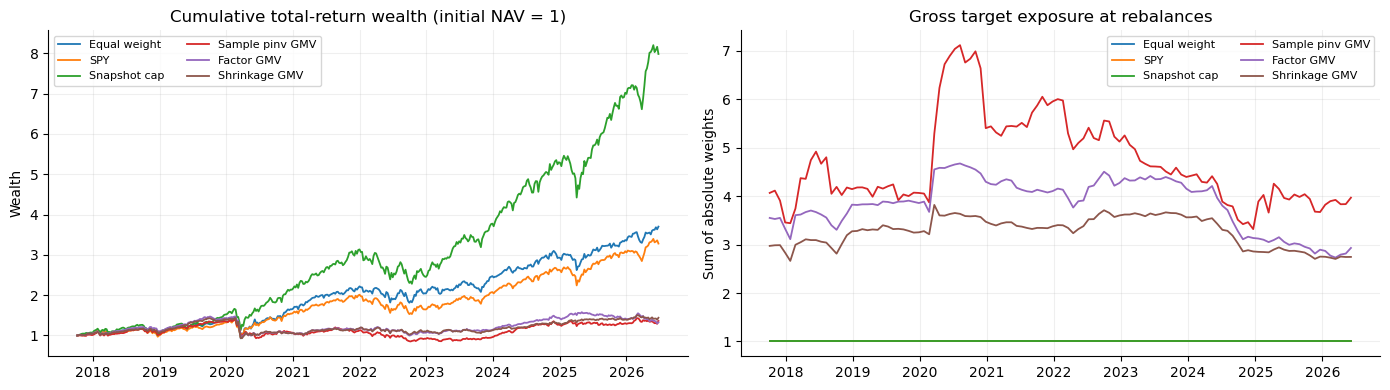

In [8]:
# Optimize the three unconstrained books under their own covariance at every signal date.
gmv_names = ['Sample pinv GMV', 'Factor GMV', 'Shrinkage GMV']
gmv_weights = {label: [] for label in gmv_names}
gmv_predictions = {label: [] for label in gmv_names}
for date in rebalance_dates:
    x, _ = window_at(date)
    sample = x.cov().to_numpy()
    model = weekly_models[date]
    factor = factor_covariance(model)
    shrunk = 0.5 * sample + 0.5 * np.diag(np.diag(sample))
    candidates = {
        'Sample pinv GMV': (sample_gmv_weights[date], sample),
        'Factor GMV': (normalize_gmv(factor_solve(model, ones)), factor),
        'Shrinkage GMV': (spd_gmv(shrunk), shrunk),
    }
    for label, (weights, cov) in candidates.items():
        gmv_weights[label].append(weights)
        gmv_predictions[label].append(np.sqrt(52 * weights @ cov @ weights))
for label in gmv_names:
    weights = pd.DataFrame(gmv_weights[label], index=rebalance_dates, columns=tickers)
    books[label] = make_book(weights, gmv_predictions[label])
gmv_metrics = report_books({label: books[label] for label in gmv_names})

# Total-return wealth and gross exposure reveal different aspects of implementation risk.
plot_names = ['Equal weight', 'SPY', 'Snapshot cap'] + gmv_names
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for label in plot_names:
    book = books[label]
    total = book['excess'] + rf.reindex(oos_dates)
    wealth = pd.concat([pd.Series([1.0], index=[rebalance_dates[0]]), (1 + total).cumprod()])
    axes[0].plot(wealth.index, wealth, label=label, linewidth=1.3)
    axes[1].plot(rebalance_dates, book['weights'].abs().sum(axis=1), label=label, linewidth=1.3)
axes[0].set(title='Cumulative total-return wealth (initial NAV = 1)', ylabel='Wealth')
axes[1].set(title='Gross target exposure at rebalances', ylabel='Sum of absolute weights')
axes[0].legend(fontsize=8, ncol=2)
axes[1].legend(fontsize=8, ncol=2)
fig.tight_layout()
plt.show()


## 3.3

Build the long-only GMV under your factor covariance with NNLS in the regression form. Report the same metrics.

#### NNLS Formulation

For the long-only tangency portfolio, NNLS of a constant on the return panel gives the weights, as in *MV Optimization via Regression*. For the GMV under any covariance $\Sigma = \boldsymbol{L}\boldsymbol{L}'$ (a Cholesky or eigenvalue factor), the variance is $\lVert \boldsymbol{L}'\boldsymbol{w} \rVert^2$. Stack the rows of $\boldsymbol{L}'$ with one additional row $\kappa\,\mathbf{1}'$ and a target vector of zeros with a final entry $\kappa$: the least-squares objective becomes $\boldsymbol{w}'\Sigma\boldsymbol{w} + \kappa^2(1 - \mathbf{1}'\boldsymbol{w})^2$. With $\kappa$ large relative to the return scale, NNLS on that system gives the long-only GMV up to a rescaling of the weights to sum to one.


Solve the stacked NNLS system with $\kappa=100\max_i\sqrt{\Sigma_{F,ii}}$, then normalize weights to sum to one. For any nonnegative unit-budget direction $u$, the minimized penalty increases with $u'\Sigma_Fu$, so normalization preserves the long-only GMV direction in exact arithmetic.

In [9]:
def long_only_gmv(cov):
    """Solve the nonnegative regression and normalize its optimal portfolio direction."""
    chol = np.linalg.cholesky(cov)
    kappa = 100 * np.sqrt(np.diag(cov).max())
    # Cholesky gives cov = L L'; use L' so the least-squares norm equals portfolio variance.
    design = np.vstack([chol.T, kappa * np.ones(len(cov))])
    target = np.append(np.zeros(len(cov)), kappa)
    weights, _ = nnls(design, target, maxiter=10 * len(cov))
    return normalize_gmv(weights)

long_weights, long_predictions = [], []
for date in rebalance_dates:
    # Reuse the same factor estimate as the unconstrained book; only the constraint changes.
    cov = factor_covariance(weekly_models[date])
    weights = long_only_gmv(cov)
    long_weights.append(weights)
    long_predictions.append(np.sqrt(52 * weights @ cov @ weights))
long_frame = pd.DataFrame(long_weights, index=rebalance_dates, columns=tickers)
books['Long-only factor GMV'] = make_book(long_frame, long_predictions)
long_metrics = report_books({'Long-only factor GMV': books['Long-only factor GMV']})
gmv_names = ['Sample pinv GMV', 'Factor GMV', 'Shrinkage GMV', 'Long-only factor GMV']
gmv_metrics = pd.concat([gmv_metrics.loc[gmv_names[:3]], long_metrics])


,Mean,Realized vol,Sharpe,Max drawdown,Predicted vol,Realized/predicted
Long-only factor GMV,4.52%,14.53%,0.31,-31.10%,8.52%,1.71


,Gross,Net,Positions,Annual one-way turnover,Average max |w|,Absolute-weight HHI
Long-only factor GMV,1.00,1.00,36.2,2.06,12.73%,0.062


## 3.4

Compare the portfolios in 3.2 and 3.3.

- Which covariance produced the lowest realized volatility? How does realized volatility compare with predicted volatility?
- How did stabilization affect gross exposure, turnover, and concentration? In which years did it perform worst?
- What changed under the long-only constraint? Explain the result.


In [10]:
# Separate the worst return year from the year with the largest risk-underprediction ratio.
annual_records = []
for label in gmv_names:
    book = books[label]
    for year, r in book['excess'].groupby(book['excess'].index.year):
        predicted = book['predicted'][book['predicted'].index.year == year].mean()
        annual_records.append({'Book': label, 'Year': year, 'Weeks': len(r),
                               'Total return': (1 + r + rf.reindex(r.index)).prod() - 1,
                               'Realized vol': r.std(ddof=1)*np.sqrt(52),
                               'Realized/predicted': r.std(ddof=1)*np.sqrt(52)/predicted})
annual_gmv = pd.DataFrame(annual_records)
worst_years = pd.concat([
    annual_gmv.loc[annual_gmv.groupby('Book')['Total return'].idxmin()].assign(Criterion='Lowest return'),
    annual_gmv.loc[annual_gmv.groupby('Book')['Realized/predicted'].idxmax()].assign(Criterion='Largest risk miss')
]).set_index(['Book', 'Criterion'])
show_table(worst_years, {'Year': '{:.0f}', 'Weeks': '{:.0f}', 'Total return': '{:.2%}',
                         'Realized vol': '{:.2%}', 'Realized/predicted': '{:.2f}'},
           'Worst calendar-year observations; 2017 and 2026 are partial years')


,,Year,Weeks,Total return,Realized vol,Realized/predicted
Book,Criterion,,,,,
Factor GMV,Lowest return,2020,52,-26.15%,28.53%,6.12
Long-only factor GMV,Lowest return,2022,52,-5.21%,17.77%,1.81
Sample pinv GMV,Lowest return,2020,52,-20.94%,26.89%,2.54
Shrinkage GMV,Lowest return,2020,52,-24.76%,29.32%,4.62
Factor GMV,Largest risk miss,2020,52,-26.15%,28.53%,6.12
Long-only factor GMV,Largest risk miss,2018,52,-0.27%,14.57%,2.60
Sample pinv GMV,Largest risk miss,2020,52,-20.94%,26.89%,2.54
Shrinkage GMV,Largest risk miss,2020,52,-24.76%,29.32%,4.62


In [11]:
# Summarize the required comparisons using the computed tables.
lowest = gmv_metrics['Realized vol'].idxmin()
sample_row, shrink_row = gmv_metrics.loc['Sample pinv GMV'], gmv_metrics.loc['Shrinkage GMV']
factor_row, long_row = gmv_metrics.loc['Factor GMV'], gmv_metrics.loc['Long-only factor GMV']
risk_ratios = ', '.join(f'{gmv_metrics.loc[label, "Realized/predicted"]:.2f}' for label in gmv_names)
unconstrained_worst = ', '.join(str(year) for year in sorted({
    int(worst_years.loc[(label, 'Lowest return'), 'Year']) for label in gmv_names[:3]}))
long_worst = int(worst_years.loc[('Long-only factor GMV', 'Lowest return'), 'Year'])
long_miss = int(worst_years.loc[('Long-only factor GMV', 'Largest risk miss'), 'Year'])
display(Markdown('### What stabilization and constraints changed\n\n'
    f'- **Risk:** {lowest} has the lowest realized volatility '
    f'({gmv_metrics.loc[lowest, "Realized vol"]:.2%}). All four books underestimate risk: '
    f'realized/predicted ratios are {risk_ratios}, respectively, in table order.\n'
    f'- **Stabilization:** Shrinkage reduces gross exposure from {sample_row["Gross"]:.2f} '
    f'to {shrink_row["Gross"]:.2f} and annual turnover from {sample_row["Annual one-way turnover"]:.2f} '
    f'to {shrink_row["Annual one-way turnover"]:.2f}, but increases average maximum weight '
    f'from {sample_row["Average max |w|"]:.2%} to {shrink_row["Average max |w|"]:.2%}. '
    f'The unconstrained books have their worst return year in {unconstrained_worst}.\n'
    f'- **Long-only:** Gross exposure falls from {factor_row["Gross"]:.2f} to {long_row["Gross"]:.2f} '
    f'and calibration improves, while realized volatility stays similar '
    f'({factor_row["Realized vol"]:.2%} versus {long_row["Realized vol"]:.2%}). '
    'Removing short hedges raises estimated minimum risk; NNLS concentrates holdings in '
    f'about {long_row["Positions"]:.0f} names. Its worst return year is {long_worst}; '
    f'its largest risk underestimate occurs in {long_miss}.\n'
    '- **Carry-forward choice:** Retain the diagonal-residual factor covariance with long-only weights '
    'for implementation, while recognizing persistent concentration and risk underestimation.'))


### What stabilization and constraints changed

- **Risk:** Shrinkage GMV has the lowest realized volatility (14.05%). All four books underestimate risk: realized/predicted ratios are 1.75, 3.66, 2.95, 1.71, respectively, in table order.
- **Stabilization:** Shrinkage reduces gross exposure from 4.68 to 3.27 and annual turnover from 12.23 to 5.04, but increases average maximum weight from 4.41% to 5.36%. The unconstrained books have their worst return year in 2020.
- **Long-only:** Gross exposure falls from 3.84 to 1.00 and calibration improves, while realized volatility stays similar (14.46% versus 14.53%). Removing short hedges raises estimated minimum risk; NNLS concentrates holdings in about 36 names. Its worst return year is 2022; its largest risk underestimate occurs in 2018.
- **Carry-forward choice:** Retain the diagonal-residual factor covariance with long-only weights for implementation, while recognizing persistent concentration and risk underestimation.

# 4. The Mean Input


## 4.1

Build the tangency portfolio under your factor covariance with three return inputs: the sample means of the window; the sample means shrunk halfway toward the grand mean, $a = 0.5$; and the CAPM-implied means, $\beta_i$ times the window's mean market excess return, with $\beta_i$ estimated on SPY over the window. Scale each to 10% ex-ante volatility.

* Report the book metrics, including predicted and realized volatility.
* State what the $a = 1$ book is without running it.

#### Mean Shrinkage

Shrinkage toward the grand mean across names with weight $a$: $\tilde{\mu}_i^{(a)} = (1-a)\,\hat{\tilde\mu}_i + a\,\bar{\hat{\tilde\mu}}$.


In [12]:
# Hold covariance and estimation dates fixed so only the mean input differs between books.
tangency_names = ['Tangency sample mean', 'Tangency half shrink', 'Tangency CAPM']
tangency_weights = {label: [] for label in tangency_names}
tangency_predictions = {label: [] for label in tangency_names}
mean_uncertainty_rows = []
for date in rebalance_dates:
    x, _ = window_at(date)
    model = weekly_models[date]
    mu = x.mean().to_numpy()
    market = spyx.reindex(x.index).to_numpy()
    mc = market - market.mean()
    # Estimate SPY betas on this window only; the full-sample betas in Section 6 are not used.
    beta_market = mc @ (x.to_numpy() - mu) / (mc @ mc)
    inputs = [mu, 0.5*mu + 0.5*mu.mean(), beta_market*market.mean()]
    for label, mean in zip(tangency_names, inputs):
        direction = factor_solve(model, mean)
        variance = factor_variance(model, direction[:, None])[0]
        if variance <= 0:
            raise ValueError(f'Cannot volatility-scale a zero tangency direction on {date}.')
        # Scale volatility, not the budget: net exposure may differ across mean specifications.
        weights = direction * 0.10 / np.sqrt(52 * variance)
        tangency_weights[label].append(weights)
        tangency_predictions[label].append(np.sqrt(52*factor_variance(model, weights[:, None])[0]))
    # Record Section 4.2's uncertainty inputs while this historical window is already in memory.
    typical_vol = x.std(ddof=1).median()*np.sqrt(52)
    se_annual_mean = typical_vol*np.sqrt(52/len(x))
    cross_mean_sd = (x.mean()*52).std(ddof=1)
    mean_uncertainty_rows.append((date, typical_vol, se_annual_mean, cross_mean_sd, se_annual_mean/cross_mean_sd))
for label in tangency_names:
    w = pd.DataFrame(tangency_weights[label], index=rebalance_dates, columns=tickers)
    books[label] = make_book(w, tangency_predictions[label])
tangency_metrics = report_books({label: books[label] for label in tangency_names})


,Mean,Realized vol,Sharpe,Max drawdown,Predicted vol,Realized/predicted
Tangency sample mean,14.36%,42.03%,0.34,-76.72%,10.00%,4.20
Tangency half shrink,12.93%,42.77%,0.30,-80.67%,10.00%,4.28
Tangency CAPM,3.62%,11.97%,0.30,-32.71%,10.00%,1.20


,Gross,Net,Positions,Annual one-way turnover,Average max |w|,Absolute-weight HHI
Tangency sample mean,10.00,0.50,457.0,22.53,13.15%,0.004
Tangency half shrink,9.98,1.11,457.0,22.27,13.46%,0.004
Tangency CAPM,1.87,0.56,457.0,3.97,2.62%,0.004


The sample-mean and half-shrunk books lever to about 10× gross and realize roughly 42% volatility against the 10% target (realized/predicted ≈ 4.2). The CAPM book runs 1.9× gross and realizes 12.0% (ratio 1.20).

**$a = 1$, without running it.** The input becomes $\bar\mu\mathbf1$, so the direction is $\bar\mu\,\Sigma_F^{-1}\mathbf1$: the factor GMV, scaled to 10% predicted volatility. Since the factor GMV predicts about 4%, this is roughly the unit-budget GMV levered 2.5×. The sign flips if $\bar\mu < 0$.

## 4.2

Compute the standard error of a 104-week annualized mean for a name of typical volatility and compare it with the cross-sectional standard deviation of the window's annualized means. Use the two components of $\Sigma^{-1}\tilde\mu$ under each anchor to explain how the books in 4.1 change with $a$. Derive the tangency weights when the return input is the CAPM-implied mean and the covariance is a single-factor model with diagonal residuals, and say which kinds of names such a book favors.


In [13]:
# Compare estimation noise with the cross-sectional differences the optimizer is asked to exploit.
uncertainty = pd.DataFrame(mean_uncertainty_rows, columns=['Date', 'Typical annual vol', 'SE annual mean',
                                                         'Cross-sectional mean SD', 'SE / cross-sectional SD']).set_index('Date')
focus_typical = X0.std(ddof=1).median()*np.sqrt(52)
focus_se = focus_typical*np.sqrt(52/WINDOW)
focus_cross_sd = (X0.mean()*52).std(ddof=1)
uncertainty_summary = pd.DataFrame([
    [focus_typical, focus_se, focus_cross_sd, focus_se/focus_cross_sd],
    uncertainty.median().to_list(),
], index=['Window ending 2025-12-26', 'Median across rolling windows'], columns=uncertainty.columns)
show_table(uncertainty_summary, {c: ('{:.2f}' if c.startswith('SE /') else '{:.2%}') for c in uncertainty.columns})


,Typical annual vol,SE annual mean,Cross-sectional mean SD,SE / cross-sectional SD
Window ending 2025-12-26,26.05%,18.42%,20.95%,0.88
Median across rolling windows,27.98%,19.79%,17.67%,1.12


### Noise versus signal

$\operatorname{SE}(52\hat\mu)=\sigma_{\rm annual}\sqrt{52/104}\approx\sigma_{\rm annual}/\sqrt2$. For a typical volatility of 26–28%, the standard error is 18–20%, about the same as the 18–21% cross-sectional standard deviation of the window's means (median ratio 1.12). Most of the spread the optimizer exploits is noise.

### The two components and $a$

Write $\tilde\mu^{(a)}=\bar\mu\mathbf1+(1-a)(\hat\mu-\bar\mu\mathbf1)$, so
$$
\Sigma^{-1}\tilde\mu^{(a)}=\underbrace{\bar\mu\,\Sigma^{-1}\mathbf1}_{\text{GMV}}+(1-a)\underbrace{\Sigma^{-1}(\hat\mu-\bar\mu\mathbf1)}_{\text{relative bets}}.
$$
The bet term dominates: the dispersion in means is as large as the noise, and $\Sigma^{-1}$ levers it through cheap factor hedges. Halving it barely changes the direction, and the 10% volatility scaling then restores the size. So the $a=0.5$ book is almost the $a=0$ book (gross 9.98 versus 10.00, realized volatility 42.8% versus 42.0%). Only $a\to1$ removes the bets and leaves the GMV. Under the CAPM anchor the bet term is replaced by $\hat\mu_M\Sigma^{-1}\hat\beta$, which carries no stock-specific mean noise, so gross falls to 1.9.

### Single-factor CAPM weights

With $\Sigma=\sigma_M^2\beta\beta'+D$ and $\tilde\mu=\beta\mu_M$, Sherman–Morrison gives
$$
\Sigma^{-1}\beta\mu_M=\frac{\mu_M}{1+\sigma_M^2\beta'D^{-1}\beta}\,D^{-1}\beta,
\qquad\text{so}\qquad w_i\propto\operatorname{sign}(\mu_M)\,\frac{\beta_i}{\sigma^2_{\epsilon,i}}.
$$
The book favors names with high beta relative to idiosyncratic variance: high-beta stocks with little stock-specific risk. Low-beta or noisy names get little weight, and negative-beta names are shorted when $\mu_M>0$.

# 5. The Book's Own Risk

Switch to daily data. Weights in force on a trading day are those of the most recent weekly rebalance. Map tickers between the two panels; drop `ECHO`, `FLEX`, `MRVL` and `FISV`, leaving 453 names, and rescale the remaining weights to the sum they had before the drop. The daily panel holds total returns and no daily bill series ships, so each book's daily return is its total return, and every VaR forecast and hit test is on that total return.


## 5.1

Carry forward one book from Section 3 or 4 and name it; keep equal weight as the control. For each trading day from the first rebalance date, forecast the next day's 5% VaR of each book from the trailing 252 trading days, three ways:

* the historical quantile of the book's return with current weights
* normal VaR with your factor covariance fit on the daily sector returns from the `total returns` sheet
* EWMA with $\lambda = 0.94$ on the book's daily return with current weights


### One-day 5% VaR on total returns

**Carried book: Long-only factor GMV**, with equal weight as the control. Both have net exposure of one, so no daily cash return is needed. We drop ECHO, FLEX, MRVL and FISV and rescale the remaining weights to their original sum; equal weight becomes $1/453$.

**Timing.** A forecast at close $t$ reprices the 252 days ending at $t$ with current weights and is scored only on the return at $t+1$. A signal on a holiday Friday maps to the preceding trading close.

**Forecasts.** $q$ is a return quantile, VaR is $-q$, and a breach is $r_{t+1}<q$. Both normal forecasts include the trailing 252-day mean $\mu$.
- **Historical:** $q$ is the 5% sample quantile. Implied CVaR is minus the mean of returns at or below it.
- **Factor normal:** $q=\mu+z_{.05}\sigma_F$ and $\mathrm{CVaR}=-\mu+\sigma_F\phi(z_{.05})/.05$, where $\sigma_F$ comes from the ten-sector, diagonal-residual covariance fit to daily total returns.
- **EWMA:** $q=\mu+z_{.05}\sigma_E$, where $\sigma_E^2$ weights squared demeaned returns in proportion to $0.94^{\rm age}$ over the 252-day window.

In [14]:
# Map ticker punctuation and apply the brief's exclusions; stocks and factors are both total returns.
DROP_DAILY = ['ECHO', 'FLEX', 'MRVL', 'FISV']
daily_tickers = tickers[~tickers.isin(DROP_DAILY)]
daily_returns = pd.read_parquet(DAILY).sort_index()[[ticker.replace('/', '-') for ticker in daily_tickers]]
daily_returns.columns = daily_tickers
daily_factors = pd.read_excel(SECTOR_DAILY, sheet_name='total returns', index_col='date')
daily_factors = daily_factors.reindex(daily_returns.index)[factor_names]
ALPHA, DAILY_WINDOW, EWMA_LAMBDA = 0.05, 252, 0.94
z_alpha = norm.ppf(ALPHA)
ewma_weights = EWMA_LAMBDA ** np.arange(DAILY_WINDOW - 1, -1, -1)
ewma_weights /= ewma_weights.sum()

def daily_weight_schedule(weekly_weights):
    """Rescale to the pre-drop net exposure, then hold each signal's weights until the next one."""
    kept = weekly_weights.loc[:, daily_tickers]
    kept = kept.mul(weekly_weights.sum(axis=1) / kept.sum(axis=1), axis=0)
    # A holiday Friday labels information already known at the preceding trading close.
    kept.index = daily_returns.index[daily_returns.index.searchsorted(kept.index, side='right') - 1]
    return kept.reindex(daily_returns.index).ffill()

def forecast_daily(collection):
    """Forecast each book's next-day 5% VaR three ways from the trailing 252 trading days."""
    labels = list(collection)
    schedules = {label: daily_weight_schedule(book['weights']) for label, book in collection.items()}
    assets = daily_returns.to_numpy()
    factors = daily_factors.to_numpy()
    first = daily_returns.index.searchsorted(rebalance_dates[0])
    tail_multiple = norm.pdf(z_alpha) / ALPHA
    rows = []
    for i in range(max(first, DAILY_WINDOW-1), len(daily_returns)-1):
        x = assets[i-DAILY_WINDOW+1:i+1]
        w = np.column_stack([schedules[label].iloc[i].to_numpy() for label in labels])
        # Reprice the trailing history with today's weights; score only the next day's return.
        past = x @ w
        mean = past.mean(axis=0)
        realized = assets[i+1] @ w
        factor_model, _ = fit_factor(x, factors[i-DAILY_WINDOW+1:i+1])
        factor_sigma = np.sqrt(factor_variance(factor_model, w))
        ewma_sigma = np.sqrt(ewma_weights @ ((past - mean)**2))
        hist_q = np.quantile(past, ALPHA, axis=0, method='linear')
        for j, label in enumerate(labels):
            hist_cvar = -past[past[:, j] <= hist_q[j], j].mean()
            factor_cvar = -mean[j] + factor_sigma[j]*tail_multiple
            forecasts = [('Historical', hist_q[j], hist_cvar, np.nan),
                         ('Factor normal', mean[j] + z_alpha*factor_sigma[j], factor_cvar, factor_sigma[j]),
                         ('EWMA', mean[j] + z_alpha*ewma_sigma[j], np.nan, ewma_sigma[j])]
            for method, quantile, implied_cvar, sigma in forecasts:
                rows.append((daily_returns.index[i+1], label, method, realized[j], quantile,
                             implied_cvar, sigma, realized[j] < quantile))
    return pd.DataFrame(rows, columns=['Date', 'Book', 'Method', 'Return', 'Quantile',
                                       'Implied CVaR', 'Sigma', 'Hit'])

daily_risk = forecast_daily({label: books[label] for label in ['Long-only factor GMV', 'Equal weight']})
display(Markdown(f'**Daily coverage:** {len(daily_tickers)} names; '
                 f'{daily_risk.Date.nunique()} realized trading days, '
                 f'{daily_risk.Date.min().date()} to {daily_risk.Date.max().date()}.'))

**Daily coverage:** 453 names; 2186 realized trading days, 2017-10-09 to 2026-06-22.

## 5.2

Run the hit test for each book and forecast over the full period and within these windows: 2020-02-19 to 2020-04-30; calendar 2022; calendar 2023. Report

* the breach rate in each cell and the number of days in each window
* for the historical and factor-normal forecasts, the realized conditional VaR on the breach days against the CVaR the forecast implies


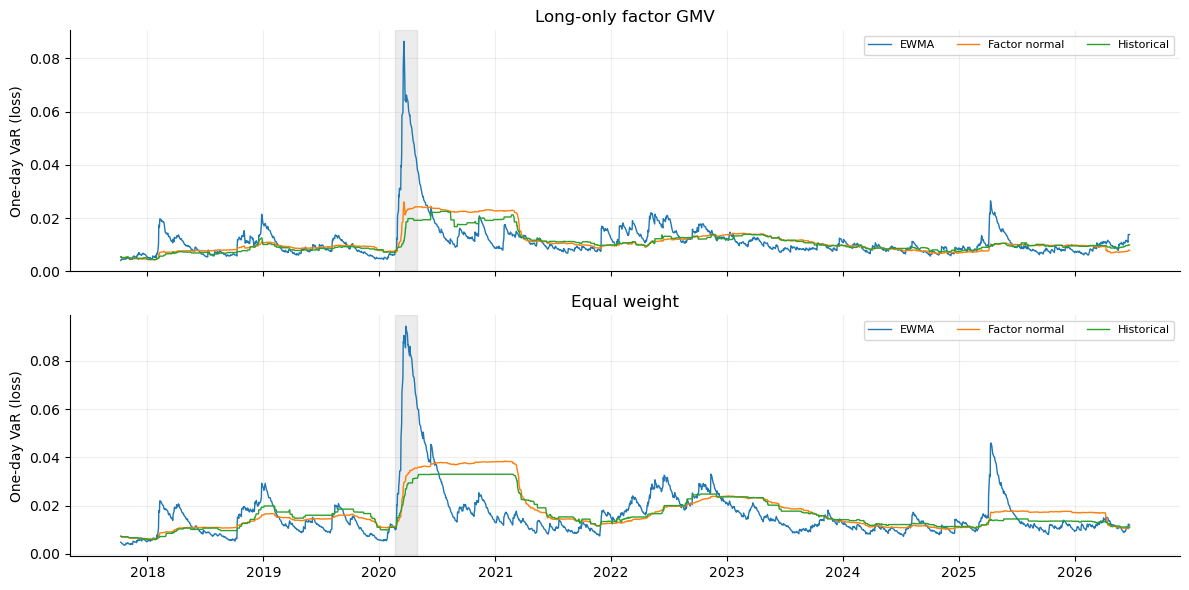

In [15]:
# A day belongs to a regime by the date of its realized return.
regimes = {'Full period': (None, None), 'COVID shock': ('2020-02-19', '2020-04-30'),
           '2022': ('2022-01-01', '2022-12-31'), '2023': ('2023-01-01', '2023-12-31')}

def summarize_hits(risk):
    records = []
    for regime, (start, end) in regimes.items():
        subset = risk if start is None else risk[risk.Date.between(start, end)]
        for (book, method), group in subset.groupby(['Book', 'Method']):
            hits = group[group.Hit]
            records.append({'Regime': regime, 'Book': book, 'Method': method, 'Days': len(group),
                            'Breach rate': len(hits)/len(group),
                            'Realized CVaR': -hits.Return.mean(),
                            'Implied CVaR': hits['Implied CVaR'].mean()})
    return pd.DataFrame(records)

def show_hit_tables(summary, book_order):
    """Report breach rates by regime, and realized against implied CVaR on each method's breach days."""
    methods = ['Historical', 'Factor normal', 'EWMA']
    rates = summary.pivot(index='Regime', columns=['Book', 'Method'], values='Breach rate')
    rates = rates.reindex(index=list(regimes), columns=pd.MultiIndex.from_product([book_order, methods]))
    days = summary.groupby('Regime')['Days'].first()
    rates.index = [f'{regime} ({days[regime]} days, {days[regime]*ALPHA:.1f} expected breaches)' for regime in regimes]
    show_table(rates, '{:.2%}', 'Breach rate; target = 5%')
    tails = summary[summary.Method != 'EWMA'].pivot(index=['Regime', 'Book'], columns='Method',
                                                    values=['Realized CVaR', 'Implied CVaR']).swaplevel(axis=1)
    tails = tails.reindex(index=pd.MultiIndex.from_product([list(regimes), book_order]),
                          columns=pd.MultiIndex.from_product([methods[:2], ['Realized CVaR', 'Implied CVaR']]))
    show_table(tails, '{:.2%}', 'Average daily loss on breach days against the CVaR implied on those days')

hit_summary = summarize_hits(daily_risk)
show_hit_tables(hit_summary, ['Long-only factor GMV', 'Equal weight'])

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
for ax, label in zip(axes, ['Long-only factor GMV', 'Equal weight']):
    for method, subset in daily_risk[daily_risk.Book == label].groupby('Method'):
        ax.plot(subset.Date, -subset.Quantile, label=method, linewidth=1)
    ax.set(title=label, ylabel='One-day VaR (loss)')
    ax.axvspan(pd.Timestamp('2020-02-19'), pd.Timestamp('2020-04-30'), color='grey', alpha=0.15)
    ax.legend(ncol=3, fontsize=8)
fig.tight_layout()
plt.show()

## 5.3

Which forecasts miss their target breach rate, for which portfolio, and through which estimated risk quantity? What does sharing one window between the choice of weights and the estimate of their risk do to the historical quantile? What can the number of days in each regime window establish, and what can it not?


In [16]:
# Compare realized volatility with forecast volatility, and check whether breaches cluster.
def daily_diagnostics(risk):
    rows = []
    for (label, method), group in risk.groupby(['Book', 'Method']):
        hit = group.Hit.to_numpy()
        realized = group.Return.std(ddof=1)*np.sqrt(252)
        forecast = np.sqrt((group.Sigma**2).mean()*252)  # Root-mean-square: averaging sigma understates variance.
        rows.append({'Book': label, 'Method': method, 'Realized vol': realized, 'Forecast vol': forecast,
                     'Realized / forecast': realized/forecast, 'Breach rate': hit.mean(),
                     'Breach rate after a breach': hit[1:][hit[:-1]].mean()})
    return pd.DataFrame(rows).set_index(['Book', 'Method'])

diagnostic_formats = {'Realized vol': '{:.2%}', 'Forecast vol': '{:.2%}', 'Realized / forecast': '{:.2f}',
                      'Breach rate': '{:.2%}', 'Breach rate after a breach': '{:.2%}'}
show_table(daily_diagnostics(daily_risk), diagnostic_formats, 'Full period; historical VaR has no volatility forecast')

**Which forecasts miss.** Over the full period, historical and factor-normal VaR are close to 5% for equal weight (5.31%, 5.54%) and too low for the chosen book (7.14%, 7.46%). EWMA exceeds 5% for both (6.54%, 6.95%). Every forecast exceeds 5% in COVID (16–31%) and 2022 (6.8–10.4%). In 2023, historical and factor-normal VaR become conservative (1.2% for equal weight, 2.8% for the chosen book), while EWMA stays above 5% (6.0%, 7.2%). The full-period average hides these offsetting regimes.

**Through which quantity.** Historical VaR depends on a quantile set by about 13 tail observations, and equal weighting makes it slow to adjust. Factor-normal VaR depends on estimated volatility and a normal tail. Realized volatility is 1.21× the factor forecast for the chosen book and 1.01× for equal weight, so the miss is mainly volatility on the optimized book. The tail also matters: realized CVaR on breach days exceeds the normal CVaR for both books (1.70% vs 1.22%; 2.50% vs 1.84%), with smaller gaps for historical CVaR (1.75% vs 1.50%; 2.55% vs 2.29%). EWMA updates volatility faster, which reduces COVID breaches, but it keeps the normal tail.

**Shared window.** GMV selects weights that looked calm over the estimation window. Each 252-day risk window sits almost entirely inside the 104-week window used to choose those weights, so the historical quantile tends to look too shallow. The chosen book's 7.14% against the equal-weight control's 5.31% is consistent with this, though it doesn't isolate the cause.

**What the day counts show.** The 51 COVID days expect only 2.6 breaches, and one breach moves the rate by about 2 points. Sixteen breaches show a clear failure in that episode, but can't estimate a stable rate or rank 29% against 31%. Calendar years expect about 12.5 breaches. Breaches also cluster: the chosen book's factor-normal rate is 17.3% on the day after a breach, against 7.5% overall.

# 6. Pricing the Names


## 6.1

Over the full weekly sample, estimate each of the 457 names' beta on SPY and run these two tests of the CAPM:

* Regress the names' mean excess returns on their betas. Report the slope and intercept beside the sample market premium.
* Run the joint test of zero alphas from the DFA case on the ten sector ETFs against SPY. Report the statistic, $p$-value, $T$, $N$ and degrees of freedom.


,Estimate
Cross-sectional intercept (annual),0.33%
Cross-sectional slope (annual),14.02%
SPY premium (annual),12.34%
R-squared,25.18%


,Statistic,p-value,T,N,Degrees of freedom
DFA H: asymptotic chi-square,14.3227,0.1588,559,10,10
GRS: finite-sample F reference,1.4066,0.1735,559,10,"(10, 548)"


,Annual alpha,Market beta
XLK,6.36%,1.179
XLI,-0.54%,1.048
XLF,-2.11%,1.080
XLRE,-4.26%,0.894
XLE,-1.69%,0.927
XLY,-3.52%,1.145
XLB,-2.89%,0.987
XLV,-0.69%,0.737
XLU,1.56%,0.635
XLP,-0.86%,0.569


Stock cross section: **T=573, N=457**, 2015-07-10 to 2026-06-26. Sector joint test: **T=559, N=10**, 2015-10-16 to 2026-06-26; XLRE availability determines the common start. No ETF returns are backfilled.

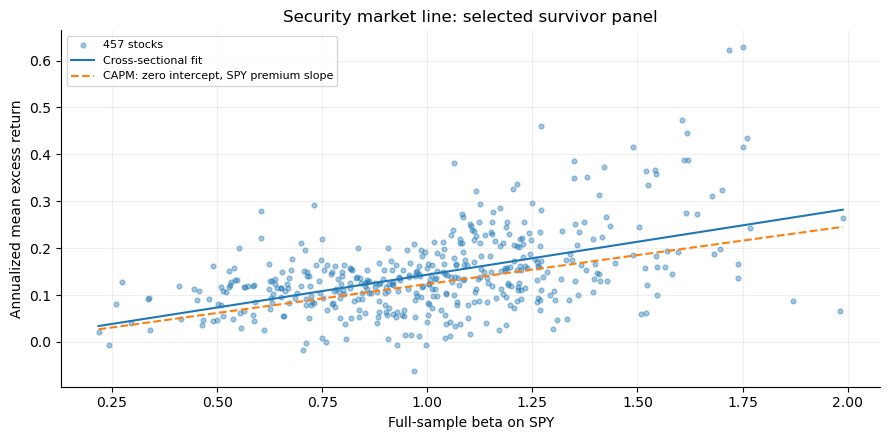

In [17]:
# Test 1: estimate every stock's beta on the same full weekly sample, then price the cross section.
market = spyx.to_numpy()
mc = market - market.mean()
betas_full = mc @ (rx.to_numpy() - rx.mean().to_numpy()) / (mc @ mc)
annual_means = rx.mean().to_numpy() * 52
cs_design = np.column_stack([np.ones(N), betas_full])
cs_intercept, cs_slope = np.linalg.lstsq(cs_design, annual_means, rcond=None)[0]
cs_fitted = cs_design @ np.array([cs_intercept, cs_slope])
cs_r2 = 1 - np.sum((annual_means-cs_fitted)**2)/np.sum((annual_means-annual_means.mean())**2)
market_premium = spyx.mean()*52
capm_cross_section = pd.Series({'Cross-sectional intercept (annual)': cs_intercept,
                               'Cross-sectional slope (annual)': cs_slope,
                               'SPY premium (annual)': market_premium,
                               'R-squared': cs_r2}, name='Estimate')
show_table(capm_cross_section.to_frame(), '{:.2%}')

# Test 2: use the ten ETFs' common available dates; do not backfill XLRE's missing early history.
joint_data = fx.join(spyx.rename('SPY')).dropna()
m = joint_data['SPY'].to_numpy()
y = joint_data[factor_names].to_numpy()
T_joint, N_joint, K_joint = len(y), y.shape[1], 1
design = np.column_stack([np.ones(T_joint), m])
coefficients = np.linalg.lstsq(design, y, rcond=None)[0]
alphas = coefficients[0]
residuals = y - design @ coefficients
residual_cov = residuals.T @ residuals / (T_joint - 1)
market_var = m.var(ddof=1)
# Follow the local DFA case's T-1 covariance convention and unannualized market Sharpe ratio.
H_dfa = T_joint / (1 + m.mean()**2/market_var) * alphas @ np.linalg.solve(residual_cov, alphas)
p_dfa = chi2.sf(H_dfa, N_joint)
# The exact GRS F reference uses T-denominator residual and factor moments.
residual_cov_ml = residuals.T @ residuals / T_joint
market_var_ml = np.var(m, ddof=0)
grs = (T_joint-N_joint-K_joint)/N_joint * (alphas @ np.linalg.solve(residual_cov_ml, alphas)) / (1+m.mean()**2/market_var_ml)
p_grs = f_dist.sf(grs, N_joint, T_joint-N_joint-K_joint)
joint_results = pd.DataFrame({
    'Statistic': [H_dfa, grs], 'p-value': [p_dfa, p_grs], 'T': [T_joint]*2, 'N': [N_joint]*2,
    'Degrees of freedom': [str(N_joint), f'({N_joint}, {T_joint-N_joint-K_joint})'],
}, index=['DFA H: asymptotic chi-square', 'GRS: finite-sample F reference'])
show_table(joint_results, {'Statistic': '{:.4f}', 'p-value': '{:.4g}', 'T': '{:.0f}',
                           'N': '{:.0f}', 'Degrees of freedom': '{}'})
show_table(pd.DataFrame({'Annual alpha': alphas*52, 'Market beta': coefficients[1]}, index=factor_names),
           {'Annual alpha': '{:.2%}', 'Market beta': '{:.3f}'})
display(Markdown(f'Stock cross section: **T={len(rx)}, N={N}**, {rx.index[0].date()} to {rx.index[-1].date()}. '
                 f'Sector joint test: **T={T_joint}, N={N_joint}**, '
                 f'{joint_data.index[0].date()} to {joint_data.index[-1].date()}; '
                 'XLRE availability determines the common start. No ETF returns are backfilled.'))

# Contrast the empirical fit with CAPM's restriction, not merely with another fitted line.
grid = np.linspace(betas_full.min(), betas_full.max(), 100)
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.scatter(betas_full, annual_means, s=12, alpha=0.4, label='457 stocks')
ax.plot(grid, cs_intercept + cs_slope*grid, label='Cross-sectional fit')
ax.plot(grid, market_premium*grid, linestyle='--', label='CAPM: zero intercept, SPY premium slope')
ax.set(xlabel='Full-sample beta on SPY', ylabel='Annualized mean excess return', title='Security market line: selected survivor panel')
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()


## 6.2

Interpret the two tests together. Compare the cross-sectional slope with the market premium and with the pattern in *CAPM on 49 Industry Portfolios*; if they differ, name a feature of this panel that could produce the difference. What do the CAPM-implied means of 4.1 assume, and how does this evidence bear on that choice of return input?


**Reading the tests together.** On average the cross-section looks CAPM-like: a 14.0% slope against a 12.3% SPY premium and a 0.3% intercept. But beta explains only 25% of the variation in mean returns, so individual names carry large pricing errors. The sector test aggregates these away and does not reject zero alphas ($H = 14.3$, $p = 0.16$), even with XLK at +6.4% a year.

**Comparison with the 49-industry case.** The industry cross-section has a shallow slope and a large positive intercept, so high-beta industries are under-rewarded. Here the slope is steep and the intercept near zero.

**Survivorship could produce the difference.** The panel holds today's S&P 500 members with complete histories since 2015, so high-beta names that failed are missing. Since $\hat\lambda = \bar r_M + \operatorname{Cov}(\hat\beta,\hat\alpha)/\operatorname{Var}(\hat\beta)$, positive realized alphas among high-beta survivors push the slope above the premium.

**Implication for 4.1.** CAPM-implied means assume zero expected alpha for every name, stable 104-week betas, and a window premium that persists into the holding period. The evidence supports CAPM as an anchor for the level of beta compensation, consistent with the CAPM book's best calibration in 4.1 (ratio 1.20). The low $R^2$ warns that zeroing every alpha discards stock-specific differences.

# 7. Build Your Book

Choose a portfolio using the evidence above. The covariance model, return input, constraints, and objective are decisions to justify; a higher realized Sharpe ratio alone does not establish a better design.


## 7.1

Before testing, declare in one table:

* the universe: the 457 static names, the full panel with membership changing as histories begin, or a subset
* the covariance and any stabilization, and the mean treatment, or none
* the constraints: long-only, position caps, a gross limit, sector neutrality
* the objective: variance, or a tail measure if you bring a solver
* the window length, rebalance frequency and a one-way cost per unit turnover in basis points
* the evaluation rule, which must include the ratio of realized to predicted volatility and the VaR breach rate of the book, alongside whatever return metrics you choose against the two benchmarks

Use the declared rule to evaluate the portfolio. The design is informed by Sections 2 to 6; although each rolling estimate uses past data, the overall design has not been tested on an untouched sample.


### Four workstreams, four decisions

| Contributor | Takeaway from the earlier results | Implication for our own book |
|---|---|---|
| **Parts 1–2: covariance (C)** | The sample matrix is singular; residual dependence remains, but full blocks worsen unconstrained own-GMV calibration. | Retain ten factors and **50% of within-sector residual off-diagonals** as a bias–variance compromise. |
| **Part 3: portfolio construction (P)** | Long-only removes leverage, not concentration: about 36 positions, mean largest weight 12.73%, risk ratio 1.706. | Mix the long-only optimized sleeve **50:50 with EW** to moderate optimization and turnover. |
| **Parts 4 and 6: means and pricing (M)** | Mean-estimation noise is comparable to observed dispersion. CAPM stabilizes tangency, and sector alphas are not rejected, but neither result establishes individual expected alpha. | Use **no individual mean signal** for the variance mandate; assess a constrained sample-mean counterfactual. |
| **Part 5: daily risk (R)** | Slow forecasts miss regime changes; EWMA adapts faster but retains tail errors. | Update **factor volatility scales** with daily EWMA relative volatility, retaining factor correlations; evaluate frequency and severity separately. |

### Main design declaration — before evaluation

| Item | Declared integrated book |
|---|---|
| Universe and factors | 457 static complete-weekly-history stocks; ten sector ETFs excluding XLC; current supplied GICS groups |
| Covariance | C: residual retention lambda=0.5. R: diagonal factor-volatility rescaling from 252 past daily observations, EWMA decay 0.94; retain the factor correlations and weekly residual estimates |
| Mean and objective | M: no individual mean forecast; raw sleeve minimizes estimated variance |
| Constraints and final weights | Long-only raw sleeve, unit budget; P: alpha=0.5 in EW/optimized-weight mixing; no added caps or sector neutrality; final gross and net exposure both one |
| Timing | Trailing 104-week regressions; every-four-week signals from 2017-10-06; only subsequent weekly returns earn new weights; use daily information available at that signal's last trading close |
| Costs | 10 bp per unit one-way target turnover, charged the first following week; initial establishment and full interim target-maintenance trading are excluded |
| Required sensitivity | Change **only the weekly regression window to 78 weeks**; retain 252 daily observations for the risk-scale update and daily VaR, and keep all evaluation dates/parameters fixed |
| Risk rule | Both gross realized / mean own-model predicted annual volatility in **[0.80, 1.20]** and full-period own factor-normal 5% VaR breaches in **[3%, 7%]**; thresholds unchanged |
| Evaluation | Net mean, volatility, Sharpe, total-return drawdown, predicted risk, exposure, positions, largest weights, HHI, sectors, turnover and cost; compare original LO factor GMV, EW and SPY |
| Daily risk | Project each stock book to the mandated 453 names; 252-day total-return forecasts; full period, COVID, 2022 and 2023. Report own, same-holdings original-model, historical and EWMA forecasts with tail severity |
| Attribution | Only four single-policy contrasts: remove C, P or R, or replace M with sample means at fixed gamma=10. No interaction experiment or parameter search |

The bands are engineering tolerances, not statistical tests. These choices reuse the era examined in Parts 2–6 and are **exploratory**, despite historical rolling inputs. Gamma=10 is fixed for the mean-policy contrast, not optimized. SPY is a weekly benchmark; unavailable stock-level look-through and factor VaR are not imputed.

### Portfolio specification

We combine the covariance and risk adjustments as

$$
\Sigma_t^*
=
B_t'A_t\widehat\Sigma_{f,t}A_tB_t
+(1-\lambda)D_t+\lambda S_{\epsilon,t}^{block},
\qquad \lambda=0.5.
$$

Here, $D_t$ contains residual variances and $S_{\epsilon,t}^{block}$ retains within-sector residual covariances. The diagonal matrix $A_t$ rescales factor volatilities using the square root of the ratio of EWMA to sample variance, calculated from the same trailing 252 daily observations with EWMA decay 0.94.

Let $u_t$ be the long-only, fully invested GMV portfolio under $\Sigma_t^*$. The final portfolio blends this allocation equally with equal weight:

$$
w_t=(1-\alpha)\frac{\mathbf{1}}{N}+\alpha u_t,
\qquad \alpha=0.5.
$$

The main book uses no expected-return signal. Its predicted variance is computed directly as $w_t'\Sigma_t^*w_t$, including the covariance between the two components.

## 7.2

Build the book on the rolling protocol with your window and rebalance frequency and report it under your rule. Then change one thing, the window length or the universe, and report what changed.


In [18]:
from scipy.linalg import eigvalsh, solve_triangular
from scipy.optimize import brentq
from IPython.display import HTML

COST_BPS, GAMMA = 10.0, 10.0
MAIN, SHORT, BASE = 'Integrated book', 'Integrated (78w)', 'Original LO GMV'
NO_C, NO_P, NO_M, NO_R = 'No C: diagonal residuals', 'No P: no EW blend', 'No M: sample means', 'No R: static factor risk'
# One main design, one required window test and four necessary single-policy contrasts.
specs = {
    MAIN:  dict(length=104, lam=0.5, alpha=0.5, use_means=False, adaptive=True),
    SHORT: dict(length=78,  lam=0.5, alpha=0.5, use_means=False, adaptive=True),
    BASE:  dict(length=104, lam=0.0, alpha=1.0, use_means=False, adaptive=False),
    NO_C:  dict(length=104, lam=0.0, alpha=0.5, use_means=False, adaptive=True),
    NO_P:  dict(length=104, lam=0.5, alpha=1.0, use_means=False, adaptive=True),
    NO_M:  dict(length=104, lam=0.5, alpha=0.5, use_means=True,  adaptive=True),
    NO_R:  dict(length=104, lam=0.5, alpha=0.5, use_means=False, adaptive=False),
}

def factor_scale_update(history):
    """Relative daily factor volatility; no future observations or absolute unit conversion."""
    f = np.asarray(history)
    if f.shape != (DAILY_WINDOW, len(factor_names)) or not np.isfinite(f).all():
        raise ValueError('Factor scale update needs 252 complete daily observations on the ten factors.')
    centered = f - f.mean(axis=0)
    sample_var = np.sum(centered**2, axis=0)/(len(f)-1)
    ewma_var = ewma_weights @ (centered**2)
    if np.any(sample_var <= 0) or np.any(ewma_var <= 0):
        raise ValueError('Nonpositive factor variance in the relative-volatility update.')
    return np.sqrt(ewma_var/sample_var)

def solve_sleeve(cov, mean, use_means, context):
    """Use NNLS for GMV; a convex constrained QP tests removal of the mean guard."""
    scale = np.diag(cov).max()
    if not np.isfinite(cov).all() or scale <= 0 or np.max(np.abs(cov-cov.T)) > 1e-10*scale:
        raise ValueError(f'Invalid covariance: {context}.')
    min_eig = eigvalsh(cov, subset_by_index=[0, 0])[0]
    if min_eig <= 0:
        raise ValueError(f'Non-SPD covariance: {context}; minimum eigenvalue {min_eig}.')
    linear = mean/GAMMA if use_means else np.zeros(len(cov))
    if use_means:
        # For each budget multiplier, the nonnegative quadratic problem is exactly NNLS.
        chol = np.linalg.cholesky(cov)
        target_mean = solve_triangular(chol, linear, lower=True)
        target_budget = solve_triangular(chol, np.ones(len(cov)), lower=True)
        def weights_at(multiplier):
            return nnls(chol.T, target_mean-multiplier*target_budget, maxiter=10*len(cov))[0]
        # The optimal multiplier lies between min(linear)-max(diag(cov)) and max(linear).
        multiplier = brentq(lambda value: weights_at(value).sum()-1,
                            linear.min()-2*scale, linear.max()+scale, xtol=1e-14*scale)
        w = weights_at(multiplier)
    else:
        w = long_only_gmv(cov)
    if not np.isfinite(w).all() or w.min() < 0 or abs(w.sum()-1) > 1e-9:
        raise ValueError(f'Invalid nonnegative unit-budget sleeve: {context}.')
    # KKT applies to the raw optimum, not the deliberately mixed final portfolio.
    marginal = cov@w-linear
    common = w@marginal
    active = w > 1e-8
    gap = max(0.0, common-marginal[~active].min()) if (~active).any() else 0.0
    error = max(np.abs(marginal[active]-common).max(), gap)/scale
    if error > 2e-6:
        raise RuntimeError(f'Portfolio optimality check failed at {context}: {error}.')
    return w

# Reuse fits across contrasts and avoid retaining hundreds of full 457 x 457 matrices.
weight_rows = {label: [] for label in specs}
predictions = {label: [] for label in specs}
reference_predictions = {label: [] for label in specs}
for length in (104, 78):
    labels = [label for label, spec in specs.items() if spec['length'] == length]
    for date in rebalance_dates:
        x, f = window_at(date, length)
        model, residuals = fit_factor(x, f)
        beta, fcov, d = model
        multiplier = factor_scale_update(daily_factors.loc[:date].tail(DAILY_WINDOW))
        block, diagonal = residual_blocks(residuals), np.diag(d)
        systematic = beta.T@fcov@beta
        adjusted = beta.T@(multiplier[:, None]*fcov*multiplier[None, :])@beta
        solved = {}
        for label in labels:
            spec = specs[label]
            lam, alpha = spec['lam'], spec['alpha']
            resid_cov = (1-lam)*diagonal+lam*block
            cov = (adjusted if spec['adaptive'] else systematic)+resid_cov
            key = (lam, spec['adaptive'], spec['use_means'])
            if key not in solved:
                solved[key] = solve_sleeve(cov, x.mean().to_numpy(), spec['use_means'], (date, length, key))
            u = solved[key]
            w = (1-alpha)/N+alpha*u
            weight_rows[label].append(w)
            predictions[label].append(np.sqrt(52*w@cov@w))
            reference_predictions[label].append(np.sqrt(52*factor_variance(model, w[:, None])[0]))

# Apply the original return, timing and target-turnover cost conventions without editing their helpers.
final_books = {}
for label in specs:
    weights = pd.DataFrame(weight_rows[label], index=rebalance_dates, columns=tickers)
    book = make_book(weights, predictions[label], cost_bps=COST_BPS)
    book['reference_predicted'] = pd.Series(reference_predictions[label], index=rebalance_dates)
    final_books[label] = book
for label in ['Equal weight', 'SPY']:
    original = books[label]
    panel = spyx.to_frame('SPY') if label == 'SPY' else rx
    book = make_book(original['weights'], original['predicted'], panel, cost_bps=COST_BPS)
    book['reference_predicted'] = book['predicted'].copy()
    final_books[label] = book
main_labels = [MAIN, SHORT, BASE, 'Equal weight', 'SPY']
final_metrics = pd.DataFrame({label: book_metrics(book) for label, book in final_books.items()}).T
display(Markdown('### Main book and required window sensitivity\n\n'
                 'The 78-week row changes only the regression window; all 455 holding weeks and daily-risk settings match.'))
report_books({label: final_books[label] for label in main_labels});

### Main book and required window sensitivity

The 78-week row changes only the regression window; all 455 holding weeks and daily-risk settings match.

,Mean,Realized vol,Sharpe,Max drawdown,Predicted vol,Realized/predicted
Integrated book,8.76%,15.73%,0.56,-33.06%,11.54%,1.36
Integrated (78w),8.75%,15.89%,0.55,-33.20%,11.10%,1.43
Original LO GMV,4.31%,14.53%,0.30,-31.12%,8.52%,1.71
Equal weight,14.23%,19.33%,0.74,-36.20%,17.98%,1.08
SPY,12.61%,18.03%,0.70,-31.83%,17.02%,1.06


,Gross,Net,Positions,Annual one-way turnover,Average max |w|,Absolute-weight HHI
Integrated book,1.00,1.00,457.0,1.95,6.03%,0.016
Integrated (78w),1.00,1.00,457.0,2.07,6.22%,0.016
Original LO GMV,1.00,1.00,36.2,2.06,12.73%,0.062
Equal weight,1.00,1.00,457.0,0.00,0.22%,0.002
SPY,1.00,1.00,1.0,0.00,100.00%,1.000


In [19]:
def book_model_forecasts(collection):
    """Section 5's factor-normal forecast, with each book's declared residual retention and factor scaling."""
    labels = list(collection)
    settings = [specs.get(label, dict(lam=0.0, adaptive=False)) for label in labels]
    lam = np.array([s['lam'] for s in settings])
    adaptive = np.array([s['adaptive'] for s in settings])
    schedules = {label: daily_weight_schedule(book['weights']) for label, book in collection.items()}
    daily_sectors = sector_labels.reindex(daily_tickers).to_numpy()
    groups = [np.flatnonzero(daily_sectors == sector) for sector in sector_groups]
    assets, factors = daily_returns.to_numpy(), daily_factors.to_numpy()
    first = daily_returns.index.searchsorted(rebalance_dates[0])
    tail_multiple = norm.pdf(z_alpha) / ALPHA
    rows = []
    for i in range(max(first, DAILY_WINDOW-1), len(daily_returns)-1):
        x, f = assets[i-DAILY_WINDOW+1:i+1], factors[i-DAILY_WINDOW+1:i+1]
        w = np.column_stack([schedules[label].iloc[i].to_numpy() for label in labels])
        mean = (x @ w).mean(axis=0)
        realized = assets[i+1] @ w
        (beta, fcov, d), residuals = fit_factor(x, f)
        exposure = beta @ w
        scale = factor_scale_update(f)
        scaled_fcov = scale[:, None]*fcov*scale[None, :]
        systematic = np.where(adaptive, np.sum(exposure*(scaled_fcov @ exposure), axis=0),
                              np.sum(exposure*(fcov @ exposure), axis=0))
        diagonal = np.sum(d[:, None]*w**2, axis=0)
        block = sum(np.sum((residuals[:, g] @ w[g])**2, axis=0)/(DAILY_WINDOW-1) for g in groups)
        sigma = np.sqrt(systematic + (1-lam)*diagonal + lam*block)
        for j, label in enumerate(labels):
            quantile = mean[j] + z_alpha*sigma[j]
            rows.append((daily_returns.index[i+1], label, 'Book model', realized[j], quantile,
                         -mean[j] + sigma[j]*tail_multiple, sigma[j], realized[j] < quantile))
    return pd.DataFrame(rows, columns=['Date', 'Book', 'Method', 'Return', 'Quantile', 'Implied CVaR', 'Sigma', 'Hit'])

# Section 5's forecasts are the baseline; the book model adds what Section 5 suggested changing.
stock_books = {label: book for label, book in final_books.items() if label != 'SPY'}
final_daily_risk = pd.concat([forecast_daily(stock_books), book_model_forecasts(stock_books)], ignore_index=True)
final_hit_summary = summarize_hits(final_daily_risk)
full_hits = final_hit_summary[final_hit_summary.Regime == 'Full period'].set_index(['Book', 'Method'])

evaluation_rows = []
for label, book in final_books.items():
    gross = book['gross_excess'].std(ddof=1)*np.sqrt(52)
    own_ratio = gross/book['predicted'].mean()
    ref_ratio = gross/book['reference_predicted'].mean()
    hit = full_hits.loc[(label, 'Book model'), 'Breach rate'] if label != 'SPY' else np.nan
    ref_hit = full_hits.loc[(label, 'Factor normal'), 'Breach rate'] if label != 'SPY' else np.nan
    screen = ('Pass' if 0.8 <= own_ratio <= 1.2 and 0.03 <= hit <= 0.07 else 'Fail') if label != 'SPY' else 'Not scored'
    evaluation_rows.append({'Book': label, 'Gross vol': gross, 'Gross / own': own_ratio,
                            'Gross / original model': ref_ratio, 'Own FN hits': hit, 'Original-model FN hits': ref_hit,
                            'Annual cost (bp)': book['costs'].mean()*52*10000,
                            'Peak max |w|': book['weights'].abs().to_numpy().max(), 'Risk screen': screen})
evaluation = pd.DataFrame(evaluation_rows).set_index('Book')
evaluation_formats = {'Gross vol': '{:.2%}', 'Gross / own': '{:.3f}', 'Gross / original model': '{:.3f}',
                      'Own FN hits': '{:.3%}', 'Original-model FN hits': '{:.3%}', 'Annual cost (bp)': '{:.2f}',
                      'Peak max |w|': '{:.2%}', 'Risk screen': '{}'}
show_table(evaluation.loc[main_labels].drop(columns='Gross vol'), evaluation_formats,
           'Unchanged joint screen: gross risk ratio 0.80–1.20 and own factor-normal breaches 3%–7%')

,Gross / own,Gross / original model,Own FN hits,Original-model FN hits,Annual cost (bp),Peak max |w|,Risk screen
Book,,,,,,,
Integrated book,1.364,1.229,6.404%,5.398%,19.38,14.48%,Fail
Integrated (78w),1.432,1.279,6.542%,5.535%,20.60,13.77%,Fail
Original LO GMV,1.706,1.706,7.457%,7.457%,20.50,20.37%,Fail
Equal weight,1.075,1.075,5.535%,5.535%,0.00,0.22%,Pass
SPY,1.060,1.060,--,--,0.00,100.00%,Not scored


### From weekly volatility to daily tail risk

The weekly gross realized/predicted ratio of **1.364** still misses the risk promise. We now apply Section 5's 453-stock mapping and next-day diagnostics to test the final book's **breach frequency, crisis performance and tail-loss severity**. On identical holdings, `Book model` versus `Factor normal` changes C and R jointly; historical and EWMA forecasts remain controls. The following tables report daily results, not a replacement for the weekly screen.

In [20]:
def details_table(frame, formats, title):
    """Preserve complete numerical results without overwhelming the main comparison."""
    html = frame.style.format(formats, na_rep='--').to_html()
    display(HTML(f'<details><summary><b>{title}</b></summary>{html}</details>'))

daily_main = [MAIN, SHORT, BASE, 'Equal weight']
daily_methods = ['Historical', 'Factor normal', 'Book model', 'EWMA']
order = pd.MultiIndex.from_product([list(regimes), daily_main])
main_hits = final_hit_summary.pivot(index=['Regime', 'Book'], columns='Method', values='Breach rate')
show_table(main_hits.reindex(index=order, columns=daily_methods), '{:.2%}',
           'Breach rate; target = 5%. For the original GMV and equal weight, the book model is the Section 5 factor model')
tail_summary = final_hit_summary[final_hit_summary.Method != 'EWMA']
tails = tail_summary.pivot(index=['Regime', 'Book'], columns='Method',
                           values=['Realized CVaR', 'Implied CVaR']).swaplevel(axis=1)
show_table(tails.reindex(index=order, columns=pd.MultiIndex.from_product([daily_methods[:3], ['Realized CVaR', 'Implied CVaR']])),
           '{:.2%}', 'Average daily loss on breach days against the CVaR implied on those days')
# Rerun Section 5's diagnostics: did the book model fix what they identified?
diagnostics = daily_diagnostics(final_daily_risk[final_daily_risk.Book.isin([MAIN, BASE, 'Equal weight'])])
show_table(diagnostics, diagnostic_formats, 'Section 5 diagnostics, full period')

**Main book: Fail.** Net annual excess mean 8.76%, volatility 15.73%, Sharpe 0.557, total-return drawdown -33.06%. Gross/own predicted volatility is **1.364** and own factor-normal breaches are **6.404%**. The joint screen is not a test of expected alpha.

**Only the regression window changes to 78 weeks:** net volatility changes by +0.16 percentage points and annual target turnover by +0.12 NAV. The risk ratio becomes 1.432, factor-normal breaches 6.542%, and the screen is **Fail**. This is a matched sensitivity, not a search for a better window.

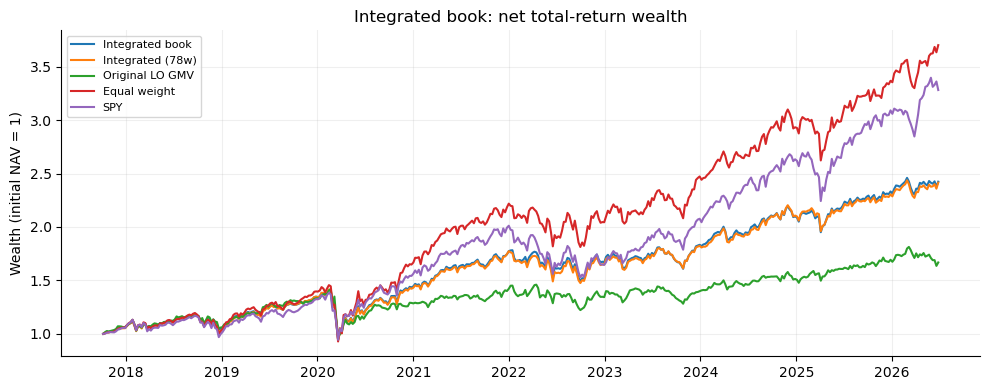

,Integrated book,Integrated (78w),Original LO GMV,Equal weight
gics_sector_name,,,,
Communication Services,6.46%,6.00%,9.84%,3.94%
Consumer Discretionary,7.46%,7.81%,5.06%,9.63%
Consumer Staples,16.19%,15.13%,27.22%,7.00%
Energy,4.06%,4.22%,3.69%,4.38%
Financials,14.24%,13.92%,13.40%,15.75%
Health Care,12.56%,12.82%,12.57%,12.25%
Industrials,10.47%,10.61%,4.74%,15.32%
Information Technology,10.91%,11.13%,7.09%,14.22%
Materials,3.72%,3.72%,2.51%,4.81%


gics_sector_name,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
Integrated book,6.46%,7.46%,16.19%,4.06%,14.24%,12.56%,10.47%,10.91%,3.72%,5.05%,8.87%
Integrated (78w),6.00%,7.81%,15.13%,4.22%,13.92%,12.82%,10.61%,11.13%,3.72%,5.21%,9.45%
Original LO GMV,9.84%,5.06%,27.22%,3.69%,13.40%,12.57%,4.74%,7.09%,2.51%,3.24%,10.63%
No C: diagonal residuals,6.71%,7.48%,16.09%,3.95%,14.65%,12.13%,10.47%,10.96%,3.61%,5.01%,8.93%
No P: no EW blend,8.99%,5.29%,25.38%,3.75%,12.72%,12.86%,5.63%,7.61%,2.62%,3.75%,11.40%
No M: sample means,6.39%,10.88%,7.66%,6.41%,10.12%,14.06%,13.58%,18.35%,3.69%,4.31%,4.55%
No R: static factor risk,6.67%,7.25%,17.20%,4.13%,14.23%,12.70%,10.08%,10.71%,3.75%,4.90%,8.38%
Equal weight,3.94%,9.63%,7.00%,4.38%,15.75%,12.25%,15.32%,14.22%,4.81%,6.35%,6.35%


SPY sector look-through weights are not supplied and are not inferred from the terminal capitalization snapshot.

In [21]:
# Evaluate the declared main book before interpreting any component contrast.
main, short = final_metrics.loc[MAIN], final_metrics.loc[SHORT]
risk, short_risk = evaluation.loc[MAIN], evaluation.loc[SHORT]
display(Markdown(f'**Main book: {risk["Risk screen"]}.** Net annual excess mean {main["Mean"]:.2%}, '
    f'volatility {main["Realized vol"]:.2%}, Sharpe {main["Sharpe"]:.3f}, total-return drawdown {main["Max drawdown"]:.2%}. '
    f'Gross/own predicted volatility is **{risk["Gross / own"]:.3f}** and own factor-normal breaches are '
    f'**{risk["Own FN hits"]:.3%}**. The joint screen is not a test of expected alpha.\n\n'
    f'**Only the regression window changes to 78 weeks:** net volatility changes by '
    f'{100*(short["Realized vol"]-main["Realized vol"]):+.2f} percentage points and annual target turnover by '
    f'{short["Annual one-way turnover"]-main["Annual one-way turnover"]:+.2f} NAV. '
    f'The risk ratio becomes {short_risk["Gross / own"]:.3f}, factor-normal breaches '
    f'{short_risk["Own FN hits"]:.3%}, and the screen is **{short_risk["Risk screen"]}**. '
    'This is a matched sensitivity, not a search for a better window.'))

fig, ax = plt.subplots(figsize=(10, 4))
for label in main_labels:
    book = final_books[label]
    wealth = (1+book['excess']+rf.reindex(oos_dates)).cumprod()
    wealth = pd.concat([pd.Series([1.0], index=[rebalance_dates[0]]), wealth])
    ax.plot(wealth.index, wealth, label=label)
ax.set(title='Integrated book: net total-return wealth', ylabel='Wealth (initial NAV = 1)')
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
sector_exposure = pd.DataFrame({label: book['weights'].T.groupby(sector_labels).sum().mean(axis=1)
                               for label, book in stock_books.items()})
show_table(sector_exposure[daily_main], '{:.2%}', 'Average sector weights: holdings, not factor beta exposures')
details_table(sector_exposure.T, '{:.2%}', 'Sector weights for all component contrasts')
display(Markdown('SPY sector look-through weights are not supplied and are not inferred from the terminal capitalization snapshot.'))


## 7.3

For each choice in 7.1, name the alternative you rejected and the evidence from Sections 2 to 6 that decided it. Close with what your evidence supports and what this sample cannot establish.


### Design choices and rejected alternatives

| Choice in 7.1 | Alternative not adopted | Evidence and justification |
|---|---|---|
| **C: 50% within-sector residual retention** | Diagonal residuals or complete sector-residual blocks | Part 2 finds residual correlation, but full blocks worsen unconstrained own-GMV calibration (mean log error **3.629 versus 2.203**). We therefore test partial retention. |
| **P: long-only, unit-budget GMV mixed 50:50 with EW** | Pure GMV or unconstrained optimization | Part 3's long-only book still has about 36 positions and a 12.73% mean largest weight. Mixing moderates concentration and turnover; no extra position caps or sector targets are imposed. |
| **M: no individual mean signal** | Sample, partially shrunk or CAPM means | Parts 4 and 6 show unstable mean estimates. CAPM means remain a plausible alternative, but are unnecessary for the variance objective. |
| **R: 0.94-EWMA relative factor-volatility scaling** | Static factor-risk forecasts | Part 5 shows crisis-period adjustment lags; relative scales target responsiveness while retaining factor correlations. |
| Static 457-name universe and ten factors | Dynamic membership, a subset or adding XLC | Keep comparisons and available history consistent with Parts 2–6. |
| 104-week window; updates every four weeks | Tuned windows or daily rebalancing | Retain Parts 2–6's common protocol, with 78 weeks as the required sensitivity test. |
| 10 bp per unit of one-way target turnover | Zero costs or a calibrated liquidity model | This is a cost scenario; Part 3's turnover makes costs material, but execution data are unavailable. |
| Volatility-ratio and VaR screen, plus CVaR | Sharpe-only evaluation | Parts 2 and 5 motivate evaluating risk calibration and tail losses alongside returns. |

### How Section 5 shapes the design and its evaluation

The optimized book's factor-normal breach rate exceeds EW's (**7.46% versus 5.54%**), supporting mixing and an EW control alongside faster risk updates. CVaR comparisons use each method's own breach days, so differences in conditional losses cannot be attributed solely to safer holdings.

### Testing the four decisions

We vary one policy at a time: **No C** sets $\lambda=0$; **No P** sets $\alpha=1$; **No R** removes adaptive scaling; and **No M** introduces sample means with $\gamma=10$. All other settings match the 104-week main book. We also compare forecasts for identical holdings to separate **combined C+R model effects** from allocation effects.

In [22]:
# Order by research question, never by ex-post performance.
contrast_labels = [MAIN, NO_C, NO_P, NO_M, NO_R]
comparison = final_metrics[['Mean', 'Realized vol', 'Absolute-weight HHI', 'Annual one-way turnover']].join(
    evaluation[['Gross / own', 'Gross / original model', 'Own FN hits', 'Annual cost (bp)']])
comparison_formats = {'Mean': '{:.2%}', 'Realized vol': '{:.2%}', 'Absolute-weight HHI': '{:.3f}',
                      'Annual one-way turnover': '{:.2f}', 'Gross / own': '{:.3f}',
                      'Gross / original model': '{:.3f}', 'Own FN hits': '{:.3%}', 'Annual cost (bp)': '{:.2f}'}
show_table(comparison.loc[contrast_labels], comparison_formats, 'Four workstreams: one-at-a-time contrasts with the integrated book')
details_table(final_metrics, '{:.4f}', 'All book metrics for the bounded attribution exercise (returns and weights in decimals)')
details_table(evaluation, evaluation_formats, 'All screening, reference-model, cost and peak-weight results')


,Mean,Realized vol,Absolute-weight HHI,Annual one-way turnover,Gross / own,Gross / original model,Own FN hits,Annual cost (bp)
Integrated book,8.76%,15.73%,0.016,1.95,1.364,1.229,6.404%,19.38
No C: diagonal residuals,8.72%,15.71%,0.016,1.93,1.367,1.231,6.496%,19.16
No P: no EW blend,3.30%,14.28%,0.057,3.90,1.831,1.560,7.045%,38.75
No M: sample means,16.69%,20.64%,0.041,2.32,1.204,1.095,7.640%,23.07
No R: static factor risk,9.40%,15.84%,0.017,1.04,1.275,1.277,5.581%,10.31


,Mean,Realized vol,Sharpe,Max drawdown,Predicted vol,Realized/predicted,Gross,Net,Positions,Annual one-way turnover,Average max |w|,Absolute-weight HHI
Integrated book,0.0876,0.1573,0.5572,-0.3306,0.1154,1.3636,1.0000,1.0000,457.0000,1.9504,0.0603,0.0158
Integrated (78w),0.0875,0.1589,0.5506,-0.3320,0.1110,1.4316,1.0000,1.0000,457.0000,2.0737,0.0622,0.0156
Original LO GMV,0.0431,0.1453,0.2968,-0.3112,0.0852,1.7062,1.0000,1.0000,36.2018,2.0639,0.1273,0.0623
No C: diagonal residuals,0.0872,0.1571,0.5548,-0.3286,0.1150,1.3668,1.0000,1.0000,457.0000,1.9288,0.0596,0.0156
No P: no EW blend,0.0330,0.1428,0.2311,-0.2985,0.0779,1.8315,1.0000,1.0000,42.5088,3.9008,0.1184,0.0566
No M: sample means,0.1669,0.2064,0.8088,-0.3511,0.1713,1.2043,1.0000,1.0000,457.0000,2.3222,0.1274,0.0411
No R: static factor risk,0.0940,0.1584,0.5936,-0.3340,0.1242,1.2755,1.0000,1.0000,457.0000,1.0379,0.0645,0.0172
Equal weight,0.1423,0.1933,0.7362,-0.3620,0.1798,1.0753,1.0000,1.0000,457.0000,0.0000,0.0022,0.0022
SPY,0.1261,0.1803,0.6994,-0.3183,0.1702,1.0596,1.0000,1.0000,1.0000,0.0000,1.0000,1.0000


,Gross vol,Gross / own,Gross / original model,Own FN hits,Original-model FN hits,Annual cost (bp),Peak max |w|,Risk screen
Book,,,,,,,,
Integrated book,15.73%,1.364,1.229,6.404%,5.398%,19.38,14.48%,Fail
Integrated (78w),15.89%,1.432,1.279,6.542%,5.535%,20.60,13.77%,Fail
Original LO GMV,14.53%,1.706,1.706,7.457%,7.457%,20.50,20.37%,Fail
No C: diagonal residuals,15.71%,1.367,1.231,6.496%,5.581%,19.16,14.48%,Fail
No P: no EW blend,14.27%,1.831,1.560,7.045%,6.176%,38.75,28.75%,Fail
No M: sample means,20.63%,1.204,1.095,7.640%,7.228%,23.07,23.52%,Fail
No R: static factor risk,15.84%,1.275,1.277,5.581%,5.581%,10.31,10.71%,Fail
Equal weight,19.33%,1.075,1.075,5.535%,5.535%,0.00,0.22%,Pass
SPY,18.03%,1.060,1.060,--,--,0.00,100.00%,Not scored


In [23]:
# Keep realized returns fixed in the last two rows; only the risk forecast changes.
attribution_rows = []
for label, prediction, method, row_name in [(BASE, 'predicted', 'Factor normal', 'Original holdings / original model'),
                                            (MAIN, 'reference_predicted', 'Factor normal', 'Main holdings / original model'),
                                            (MAIN, 'predicted', 'Book model', 'Main holdings / book model')]:
    realized = evaluation.loc[label, 'Gross vol']
    forecast = final_books[label][prediction].mean()
    attribution_rows.append((row_name, realized, forecast, realized/forecast,
                             full_hits.loc[(label, method), 'Breach rate']))
attribution = pd.DataFrame(attribution_rows, columns=['Comparison', 'Gross vol', 'Predicted vol',
                                                      'Realized/predicted', 'Daily FN hits']).set_index('Comparison')
show_table(attribution, {'Gross vol': '{:.2%}', 'Predicted vol': '{:.2%}', 'Realized/predicted': '{:.3f}',
                         'Daily FN hits': '{:.3%}'}, 'Holdings versus risk-model effects: the last two rows have identical P&L')

,Gross vol,Predicted vol,Realized/predicted,Daily FN hits
Comparison,,,,
Original holdings / original model,14.53%,8.52%,1.706,7.457%
Main holdings / original model,15.73%,12.80%,1.229,5.398%
Main holdings / book model,15.73%,11.54%,1.364,6.404%


### What the evidence supports—and its limits

**Implementation trade-offs.** EW mixing reduces HHI from 0.0566 to 0.0158 and halves annual target turnover, but raises net volatility from 14.28% to 15.73%. Sample means deliver higher realized returns at substantially higher risk, with 20.64% net volatility and a 7.64% own-model daily VaR breach rate. Residual retention shows little incremental benefit, while dynamic scaling increases costs and raises the weekly gross realized-to-mean-predicted volatility ratio relative to the static variant.

**Risk calibration remains incomplete.** On identical holdings, the combined C+R model reduces COVID breaches from 29.41% to 17.65%, but increases full-period breaches from 5.40% to 6.40%; realized CVaR still exceeds its matched breach-day forecast (1.90% versus 1.55%). Both the main and 78-week books fail the declared volatility-ratio criterion, at 1.364 and 1.432. The main book also trails EW and SPY in net mean return and Sharpe. The evidence therefore supports diversification and turnover benefits, but does not establish satisfactory risk calibration, benchmark superiority, or readiness for deployment.

**Limits and next steps.** The design reuses the evaluation sample and relies on a survivor universe, current sector classifications, overlapping windows and simplified trading costs. The daily risk tests also use a different stock universe from the weekly book. These limitations prevent claims of persistent alpha or reliable future calibration. Further validation requires a frozen design, new data, point-in-time membership and realistic execution costs.

## AI usage and verification

An AI assistant using Copilot SDK in VS Code helped draft the notebook, plan numerical routines and doublecheck explanations. Verification used clean-kernel execution and separate numerical checks. 